# Frequency Analysis Pipeline for HD35929

In [22]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [23]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# from scipy.ndimage import uniform_filter1d
import prewhiten as pw
from pathlib import Path


plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['cmr10'],
    'mathtext.fontset': 'cm',
    'axes.formatter.use_mathtext': True,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
})

In [24]:
# ----------------------------- CONFIG ------------------------------------
DATA_DIR = "/home/r1082832/ConnyProj/Analysis/Data"
OUT_DIR = "analysis_output"
OUT_DIR_B = "analysis_output_binned"
ANALYSIS_DIR = Path("/home/r1082832/ConnyProj/Analysis/Frequency_analysis")

F1_WINDOW = (0.6, 1.6)

BIN_MINUTES = 30.0 
OVERSAMPLE = 10

MC_ITER        = 500
MC_REFIT_FREQS_G = True     # ~0.83 s/iter at 20 freqs, N~4500 -> ~1.4 min/dataset
MC_REFIT_FREQS_P = True

PREDICTED = [0.7289869212399674, 2*0.7289869212399674]           # frequencies predicted BEFORE looking at the data
                         # (harmonics of a known signal, GYRE frequencies).
                         # These get n_independent = 1 -- no trials
                         # correction -- because you did not search for them,
                         # you checked one specific place. Populated below
                         # with 2*F_rot automatically.
# -------------------------------------------------------------------------
F_ROT = 0.7289869212399674
N_HARM = 2                    # subtract F_ROT and 2*F_ROT
N_HARM_REPORT = 4             # report (do not subtract) up to 4*F_ROT
 
GMODE_BAND = (0.0, 10.0)
GMODE_FLOOR = 0.10            # d^-1
GMODE_FLOOR_RAY = 3.0         # and never below 3 cycles per dataset
N_EXTRACT_G = 30              # FIXED extraction depth; assess afterwards
RN_FMAX_FRAC = 0.9            # fit the red noise out to 0.9 * Nyquist

# Frequency resolution actually used, in Rayleigh units of each dataset.
# 1.5 = Loumos & Deeming for a single run. On a merged set the inter-run gaps
# produce an alias comb, so peaks are required to be further apart -- but the
# factor is scaled so the merged search resolves exactly as well as the
# longest single run, no better and NO WORSE. A fixed factor of 50 made
# runs_2_3 (T = 347 d) resolve at 0.144 d^-1, i.e. 2.5x COARSER than a single
# 26-day run. Quote this number next to the frequency errors.
RESFAC_SINGLE = 1.5

In [25]:
# --- significance ---------------------------------------------------------
TARGET_FAP = 0.001             # band-wide FAP for a BLIND search
TARGET_FAP_PREDICTED = 1e-3   # for a frequency predicted in advance (n_ind=1)
FA_PERCENTILE = 99
INJ_TRIALS = 200
INJ_SNR_GRID = [1, 2, 3, 4, 5, 6, 8, 10]   # in units of the local noise model
 
SNR_THR_LIST = [2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
GMODE_SETS = ["Run 1", "Run 2", "Run 3", "Run 1 + Run 2", "Run 2 + Run 3", "All Combined"]
SINGLE_RUNS = ["Run 1", "Run 2", "Run 3"]
RN_REFERENCE = "All Combined"   # dataset used to fix the red-noise SHAPE
 
# --- combination search ---------------------------------------------------
COMB_MAX_N = 2                # test up to 2*F_ROT and f_i +/- 2*F_ROT
COMB_MAX_ORDER = 2
COMB_MAX_CHANCE = 0.20        # refuse to report the test above this rate

## Load Data

In [26]:
os.makedirs(OUT_DIR, exist_ok=True)


def load(name):
    d = pd.read_csv(os.path.join(DATA_DIR, name), sep=r"\s+", header=None,
                    names=["time", "flux", "flux_err"]).dropna()
    d = d.sort_values("time").reset_index(drop=True)
    return d["time"].values, d["flux"].values, d["flux_err"].values

def bin_lightcurve(t, y, e=None, bin_minutes=30.0, min_points=1):
    dt = bin_minutes / 1440.0
    idx = np.floor((np.asarray(t) - np.min(t)) / dt).astype(int)
    n  = np.bincount(idx)
    ts = np.bincount(idx, weights=t)
    ys = np.bincount(idx, weights=y)
    ok = n >= min_points
    tb, yb = ts[ok] / n[ok], ys[ok] / n[ok]
    if e is not None:
        es = np.bincount(idx, weights=np.asarray(e) ** 2)
        return tb, yb, np.sqrt(es[ok]) / n[ok]
    return tb, yb, None

runs = {"run_1.dat": "Run 1",
        "run_2.dat": "Run 2",
        "run_3.dat": "Run 3",}

data = {}

for name, label in runs.items():
    t, y, y_err = load(name)
    y_normalised = y - y.mean()
    T = t.max() - t.min()
    ray = 1.0 / T
    nyq = 0.5 / np.median(np.diff(np.sort(t)))

    tb, yb, yb_err = bin_lightcurve(t, y_normalised, y_err, bin_minutes=BIN_MINUTES)
    nyqb = 0.5 / np.median(np.diff(np.sort(tb)))

    data[label] = {
    "time": t,
    "flux": y_normalised,
    "flux_err": y_err,
    "time_binned": tb,
    "flux_binned": yb,
    "flux_err_binned": yb_err,
    "T": T,
    "Rayleigh": ray,
    "Nyquist": nyq,
    "Nyquist_binned": nyqb,
    "N": t.size,
    "N_binned": tb.size
    }

    print(f"{label}: N = {t.size}   T = {T:.4f} d  Nyquist = {nyq:.2f} d^-1  Rayleigh = {ray:.6f} d^-1")
    print(f"Binned: N = {tb.size}   T = {T:.4f} d  Nyquist = {nyqb:.2f} d^-1  Rayleigh = {ray:.6f} d^-1")
    print(80 * "-")

Run 1: N = 980   T = 21.7497 d  Nyquist = 24.00 d^-1  Rayleigh = 0.045978 d^-1
Binned: N = 980   T = 21.7497 d  Nyquist = 24.00 d^-1  Rayleigh = 0.045978 d^-1
--------------------------------------------------------------------------------
Run 2: N = 3589   T = 25.9863 d  Nyquist = 72.00 d^-1  Rayleigh = 0.038482 d^-1
Binned: N = 1198   T = 25.9863 d  Nyquist = 24.00 d^-1  Rayleigh = 0.038482 d^-1
--------------------------------------------------------------------------------
Run 3: N = 21043   T = 50.1234 d  Nyquist = 216.00 d^-1  Rayleigh = 0.019951 d^-1
Binned: N = 2350   T = 50.1234 d  Nyquist = 24.00 d^-1  Rayleigh = 0.019951 d^-1
--------------------------------------------------------------------------------


## Helpers

In [27]:
from scipy.optimize import least_squares as _lsq
 
T_SINGLE_MAX = max(data[l]["T"] for l in SINGLE_RUNS)
 
 
def is_merged(label):
    return "+" in label or "Combined" in label
 
 
def resfac(label):
    """
    Resolution factor in Rayleigh units of THIS dataset.

    For a merged set it is scaled so that resfac/T_merged == 1.5/T_single,
    i.e. the merged search resolves exactly as well as the longest single
    run. This suppresses the inter-run alias comb without silently throwing
    away resolution.
    """
    if is_merged(label):
        return RESFAC_SINGLE * data[label]["T"] / T_SINGLE_MAX
    return RESFAC_SINGLE
 
 
def resolution(label):
    return resfac(label) / data[label]["T"]
 
 
def floor_for(label):
    return max(GMODE_FLOOR, GMODE_FLOOR_RAY / data[label]["T"])
 
 
def segmented_band_D(t, resid, fmin_band, gap_days=None, min_seg=200):
    """
    Schwarzenberg-Czerny D, per contiguous segment, length-weighted.

    pw.band_D applies uniform_filter1d, which indexes by SAMPLE NUMBER and so
    assumes even sampling. On a concatenated multi-run series the boxcar
    straddles the inter-run gaps and the high-pass is wrong for a window's
    worth of points either side of each gap.
    """
    t = np.asarray(t, float)
    resid = np.asarray(resid, float)
    if gap_days is None:
        gap_days = 20.0 * np.median(np.diff(np.sort(t)))
    brk = np.flatnonzero(np.diff(t) > gap_days) + 1
    segs = [s for s in np.split(np.arange(t.size), brk) if s.size >= min_seg]
    if not segs:
        return pw.band_D(t, resid, fmin_band)
    Ds = [pw.band_D(t[s], resid[s], fmin_band) for s in segs]
    return float(np.average(Ds, weights=[s.size for s in segs]))
 
 
# --- red-noise continuum, with the shape frozen --------------------------
_RAY_MED_MEAN = np.sqrt(2 * np.log(2)) / np.sqrt(np.pi / 2)

def rn_oversample(t, fmin, min_count=3, frac=0.05, base=4):
    """
    Oversampling factor such that min_count grid steps span at most `frac` of
    fmin -- i.e. the lowest log bin is guaranteed to be populated.
    """
    ray = pw.rayleigh(t)
    return int(max(base, np.ceil(min_count * ray / (frac * fmin))))
 
def log_bin(freq, amp, n_bins=None, fmin=None, fmax=None,
            mask_freqs=None, mask_width=0.0, min_count=3):
    """Logarithmically binned MEDIAN amplitude, rescaled to the mean."""
    m = np.isfinite(freq) & np.isfinite(amp) & (freq > 0)
    if fmin is not None:
        m &= freq >= fmin
    if fmax is not None:
        m &= freq <= fmax
    if mask_freqs is not None and len(np.atleast_1d(mask_freqs)):
        for f0 in np.atleast_1d(mask_freqs):
            m &= np.abs(freq - f0) > mask_width
    f, a = freq[m], amp[m]
    if f.size < 10 * min_count:
        raise RuntimeError("too few points left after masking to bin")

    if n_bins is None:
        step = np.median(np.diff(np.sort(f)))
        ratio = 1.0 + min_count * step / f.min()      # lowest bin holds >= min_count
        n_bins = int(np.clip(np.log(f.max() / f.min()) / np.log(ratio), 12, 300))

    edges = np.logspace(np.log10(f.min()), np.log10(f.max()), n_bins + 1)
    idx = np.digitize(f, edges) - 1
    fb, ab = [], []
    for i in range(n_bins):
        s = idx == i
        if s.sum() >= min_count:
            fb.append(np.mean(f[s]))
            ab.append(np.median(a[s]) / _RAY_MED_MEAN)
    fb, ab = np.array(fb), np.array(ab)
    if fb.size < 8:
        raise RuntimeError(f"only {fb.size} usable bins")
    return fb, ab
 
 
def fit_levels(shape, fb, ab):
    """
    Refit ONLY alpha0 and C_white with nu_char and gamma held at `shape`.

    Why the shape is frozen: on a single 25-day run the low-frequency lever
    arm is one Rayleigh width wide, so alpha0 and nu_char trade off against
    each other and gamma runs to its bound. Fitting all four parameters there
    returns nonsense (measured on synthetic data: alpha0 = 208 mmag with
    nu_char = 0.02, and a real 0.13 mmag peak assigned S/N = 0.07).

    The turnover frequency and the slope are properties of the STAR, so they
    are fixed once on the dataset with the best low-frequency coverage. The
    two LEVELS depend on the dataset -- the red level on the frequency
    resolution, the white level on N -- so they are refitted per dataset.
    Two free parameters over ~150 log bins is well determined.
    """
    nuc, g = shape["nu_char"], shape["gamma"]
    shp = 1.0 / (1.0 + (fb / nuc) ** g)

    def cost(p):
        if p[0] <= 0 or p[1] <= 0:
            return np.full(fb.size, 1e6)
        return np.log(p[0] * shp + p[1]) - np.log(ab)

    hi = fb > np.median(fb)
    p0 = [max(ab.max() - np.median(ab[hi]), 1e-9), max(np.median(ab[hi]), 1e-9)]
    sol = _lsq(cost, p0, bounds=([1e-12, 1e-12], [np.inf, np.inf]),
               xtol=1e-14, ftol=1e-14)
    return float(sol.x[0]), float(sol.x[1])
 
 
def make_rn(alpha0, nu_char, gamma, C_white):
    def model(nu, a0=alpha0, nuc=nu_char, g=gamma, cw=C_white):
        return a0 / (1.0 + (np.asarray(nu, float) / nuc) ** g) + cw
    return dict(alpha0=alpha0, nu_char=nu_char, gamma=gamma,
                C_white=C_white, model=model)
 
 
def frozen_red_noise(t, y, shape, fmin, fmax, mask_width,
                     snr_threshold=4.0, max_iter=6, oversample=None,
                     verbose=True):
    """
    Iterate: fit the two levels with the current peak list masked, then
    re-identify the peaks against that continuum. `oversample` defaults to
    whatever is needed to populate the lowest bin.
    """
    if oversample is None:
        oversample = rn_oversample(t, fmin)
    f, a = pw.amplitude_spectrum(t, y, fmin=fmin, fmax=fmax,
                                 oversample=oversample, method="ls")
    peaks = np.array([])
    rn = fb = ab = None
    for it in range(max_iter):
        fb, ab = log_bin(f, a, fmin=fmin, fmax=fmax,
                         mask_freqs=peaks, mask_width=mask_width)
        a0, cw = fit_levels(shape, fb, ab)
        rn = make_rn(a0, shape["nu_char"], shape["gamma"], cw)
        above = a > snr_threshold * rn["model"](f)
        idx = np.flatnonzero(above)
        new, i = [], 0
        while i < idx.size:
            j = i
            while j + 1 < idx.size and idx[j + 1] == idx[j] + 1:
                j += 1
            seg = idx[i:j + 1]
            new.append(f[seg[np.argmax(a[seg])]])
            i = j + 1
        new = np.array(new)
        if verbose:
            print(f"    iter {it+1}: alpha0 = {a0*1e3:.5f} mmag, "
                  f"C_w = {cw*1e3:.5f} mmag, {new.size} peaks above "
                  f"{snr_threshold}x  [{fb.size} bins, ov={oversample}, "
                  f"lowest bin {fb.min():.4f} d^-1]")
        if new.size == peaks.size and (new.size == 0 or np.allclose(
                np.sort(new), np.sort(peaks), atol=1.0 / np.ptp(t))):
            break
        peaks = new
    if fb.min() > 2.0 * fmin:
        print(f"    *** lowest populated bin is {fb.min():.3f} d^-1, well "
              f"above fmin = {fmin:.3f}: alpha0 is still extrapolated. ***")
    rn["binned_freq"], rn["binned_amp"] = fb, ab
    rn["oversample"], rn["n_bins"] = oversample, fb.size
    return rn, peaks

## Remove Dominant frequency and 1st harmonic from each data set

In [28]:
# Rotation removal at FIXED frequencies.
#
#   * frequencies held at exactly F_ROT and 2*F_ROT. A true harmonic sits at
#     exactly 2f, so a floating harmonic can only fit something that is not
#     the harmonic.
#   * fundamental and harmonic fitted SIMULTANEOUSLY. On a finite,
#     non-uniform window they are not orthogonal, so sequential subtraction
#     biases the harmonic by the fundamental's leakage.
#   * no S/N gate -- always subtracted.
#   * amplitude and phase per run, because spots evolve; frequency common, so
#     the runs stay on one ephemeris.
#   * fit_sinusoids carries an offset, so each run's residual has zero mean
#     and there is no DC step at the run boundaries after concatenation.
 
HARMONICS = [(n + 1) * F_ROT for n in range(N_HARM)]
 
T0 = data["Run 3"]["time"].mean()
T0_b = data["Run 3"]["time_binned"].mean()
 
rot_rows = []
for label in SINGLE_RUNS:
    d = data[label]
    ray = d["Rayleigh"]
    free = pw.fit_sinusoids(d["time"], d["flux"], HARMONICS, refine_freqs=True, t0=T0,
                            bound_rayleigh=3.0)
 
    for suffix, tkey, ykey, t0 in [("", "time", "flux", T0),
                                   ("_binned", "time_binned", "flux_binned", T0_b)]:
        t, y = d[tkey], d[ykey]
        fit = pw.fit_sinusoids(t, y, HARMONICS, refine_freqs=False, t0=t0)
        # historical key names, so the downstream cells still work
        d[f"flux_f1_removed{suffix}"] = y - pw.evaluate_model(
            t, HARMONICS[:1], fit["amps"][:1], fit["phases"][:1],
            fit["offset"], t0)
        d[f"flux_f1_and_2f1_removed{suffix}"] = fit["resid"]
 
        if suffix == "":
            ray_r = pw.rayleigh(t)
            lo_r  = max(0.05, 3.0 * ray_r)
            fr_r, ar_r = pw.amplitude_spectrum(
                t, fit["resid"], fmin=lo_r, fmax=min(8.0, 0.9 * d["Nyquist"]),
                oversample=OVERSAMPLE, method="ls")
            snr_r = []
            for j, fn in enumerate(HARMONICS):
                nz = pw.local_noise(fr_r, ar_r, fn, box=0.5,
                                    exclude=1.5 * ray_r)
                snr_r.append(fit["amps"][j] / nz)
                print(f"        {j+1}*F_ROT = {fn:8.5f} d^-1 : "
                      f"A = {fit['amps'][j]*1e3:8.4f}, "
                      f"noise = {nz*1e3:7.5f}, S/N = {snr_r[-1]:8.2f}")
            sig_r = np.mean(ar_r) * np.sqrt(t.size / np.pi)
            D_r   = segmented_band_D(t, fit["resid"], lo_r)
            # sigma_loc = np.asarray(RN[label]["model"](HARMONICS), float) * np.sqrt(t.size/np.pi)
            err_r = pw.analytic_errors(t, fit["resid"], fit["amps"], apply_D=False)
            mc_r  = pw.monte_carlo_errors(t, HARMONICS, fit["amps"],
                                          fit["phases"], fit["offset"],
                                          fit["t0"], fit["resid"],
                                          n_iter=MC_ITER, seed=42,
                                          refit_freqs=True)   # see note
            rms0, rms1 = np.std(y, ddof=1), np.std(fit["resid"], ddof=1)
            row = {"Run": label, "N": t.size, "T_d": d["T"], "D": D_r,
                   "rms_in_mmag": rms0 * 1e3, "rms_out_mmag": rms1 * 1e3,
                   "var_removed_pct": 100 * (1 - (rms1 / rms0) ** 2)}
            for j, (A, ph) in enumerate(zip(fit["amps"], fit["phases"]), start=1):
                row[f"f{j}"]              = HARMONICS[j - 1]
                row[f"f{j}_err"]          = err_r["freq_err"][j - 1]
                row[f"f{j}_err_mc"]       = mc_r["freq_err"][j - 1]
                row[f"A{j}_mmag"]         = A * 1e3
                row[f"A{j}_err_mmag"]     = err_r["amp_err"][j - 1] * 1e3
                row[f"A{j}_err_mc_mmag"]  = mc_r["amp_err"][j - 1] * 1e3
                row[f"phi{j}"]            = ph
                row[f"phi{j}_err_mc"]     = mc_r["phase_err"][j - 1]
                row[f"snr{j}"]            = snr_r[j - 1]
                row[f"f{j}_free"]         = free["freqs"][j - 1]
                row[f"f{j}_free_ray"]     = (free["freqs"][j - 1] - HARMONICS[j - 1]) / ray
                row[f"noise{j}"]          = A / snr_r[j - 1]
            rot_rows.append(row)
 
    # --- diagnostics only -------------------------------------------------
    for j, f_fix in enumerate(HARMONICS):
        f_free = free["freqs"][j]
        print(f"{label}:  free fit of {j+1}*F_ROT lands "
              f"{(f_free - f_fix)/ray:+.2f} Rayleigh from {f_fix:.5f} "
              f"(f = {f_free:.6f} d^-1)")

    t = d["time"]

    resid = d["flux_f1_and_2f1_removed"]
    fr, ar = pw.amplitude_spectrum(t, resid, fmin=0.05, fmax=8.0,
                                   oversample=OVERSAMPLE, method="ls")
    for n in range(N_HARM + 1, N_HARM_REPORT + 1):
        fn = n * F_ROT
        if fn > 8.0:
            break
        h = pw.fit_sinusoids(t, resid, [fn], refine_freqs=False, t0=T0)
        nz = pw.local_noise(fr, ar, fn, box=1.0, exclude=1.5 * ray)
        s = h["amps"][0] / nz
        print(f"        {n}*F_ROT = {fn:7.4f} d^-1 : "
              f"A = {h['amps'][0]*1e3:7.4f} mmag, S/N = {s:5.2f}"
              + ("   <-- consider raising N_HARM" if s > 4 else ""))
    print(80 * "-")
 
df_rot = pd.DataFrame(rot_rows)
print("\n" + df_rot.to_string(index=False, float_format=lambda v: f"{v:.10f}"))
os.makedirs(OUT_DIR, exist_ok=True)
df_rot.to_csv(os.path.join(OUT_DIR, "rotation_signal.csv"), index=False)
 
A1 = df_rot["A1_mmag"].values
print(f"\nA(F_ROT) across runs: {np.array2string(A1, precision=4)} mmag  "
      f"-> spread {100*A1.std(ddof=1)/A1.mean():.1f}% of the mean.")
print("Per-run subtraction therefore removes a different amount of "
      "low-frequency power from each run; treat the merged spectrum below "
      f"~{1/df_rot['T_d'].max():.3f} d^-1 (1/T_run) with caution.")

        1*F_ROT =  0.72899 d^-1 : A =   1.6820, noise = 0.07515, S/N =    22.38
        2*F_ROT =  1.45797 d^-1 : A =   0.1429, noise = 0.04595, S/N =     3.11
Run 1:  free fit of 1*F_ROT lands -0.01 Rayleigh from 0.72899 (f = 0.728305 d^-1)
Run 1:  free fit of 2*F_ROT lands +0.09 Rayleigh from 1.45797 (f = 1.462116 d^-1)
        3*F_ROT =  2.1870 d^-1 : A =  0.0251 mmag, S/N =  0.67
        4*F_ROT =  2.9159 d^-1 : A =  0.0026 mmag, S/N =  0.09
--------------------------------------------------------------------------------
        1*F_ROT =  0.72899 d^-1 : A =   1.2191, noise = 0.08041, S/N =    15.16
        2*F_ROT =  1.45797 d^-1 : A =   0.0399, noise = 0.04099, S/N =     0.97
Run 2:  free fit of 1*F_ROT lands -0.04 Rayleigh from 0.72899 (f = 0.727612 d^-1)
Run 2:  free fit of 2*F_ROT lands -0.49 Rayleigh from 1.45797 (f = 1.439114 d^-1)
        3*F_ROT =  2.1870 d^-1 : A =  0.0227 mmag, S/N =  0.75
        4*F_ROT =  2.9159 d^-1 : A =  0.0353 mmag, S/N =  1.49
-------------------

In [29]:
f   = np.array([0.7283047365, 0.7276116540, 0.7289831391])
sig = np.maximum([3.714759e-4, 2.297700e-4, 5.63310e-5],
                 [3.060851e-4, 2.149650e-4, 6.22910e-5])
w = 1 / sig**2
m = np.sum(w * f) / w.sum()
Q = np.sum(w * (f - m) ** 2); nu = len(f) - 1

# A: Birge-scaled weighted mean
eA = w.sum() ** -0.5 * max(1.0, np.sqrt(Q / nu))

# B: random effects (DerSimonian-Laird)
tau2 = max(0.0, (Q - nu) / (w.sum() - np.sum(w**2) / w.sum()))
ws = 1 / (sig**2 + tau2)
mB, eB = np.sum(ws * f) / ws.sum(), ws.sum() ** -0.5

print(f"chi2/nu = {Q/nu:.1f}")
print(f"A: {m:.5f} +/- {eA:.5f}")
print(f"B: {mB:.5f} +/- {eB:.5f}   (tau = {np.sqrt(tau2):.4f})")

chi2/nu = 17.8
A: 0.72887 +/- 0.00025
B: 0.72832 +/- 0.00050   (tau = 0.0008)


## Concatenate Runs after F1 removal

In [30]:
# ===== UNBINNED DATA =====
# Concatenate Run 1 + Run 2
t_12 = np.concatenate([data["Run 1"]["time"], data["Run 2"]["time"]])
y_12 = np.concatenate([data["Run 1"]["flux"], data["Run 2"]["flux"]])
y_12_pw = np.concatenate([data["Run 1"]["flux_f1_and_2f1_removed"], data["Run 2"]["flux_f1_and_2f1_removed"]])
e_12 = np.concatenate([data["Run 1"]["flux_err"], data["Run 2"]["flux_err"]])
sort_idx = np.argsort(t_12)
t_12_sorted = t_12[sort_idx]
y_12_sorted = y_12[sort_idx]
y_12_pw_sorted = y_12_pw[sort_idx]
e_12_sorted = e_12[sort_idx]

T_12 = t_12_sorted.max() - t_12_sorted.min()
ray_12 = 1.0 / T_12
nyq_12 = 0.5 / np.median(np.diff(np.sort(t_12_sorted)))
data["Run 1 + Run 2"] = {
    "time": t_12_sorted,
    "flux": y_12_sorted,
    "flux_f1_and_2f1_removed": y_12_pw_sorted,
    "flux_err": e_12_sorted,
    "T": T_12,
    "Rayleigh": ray_12,
    "Nyquist": nyq_12,
    "N": t_12_sorted.size,
}

# Concatenate Run 2 + Run 3
t_23 = np.concatenate([data["Run 2"]["time"], data["Run 3"]["time"]])
y_23 = np.concatenate([data["Run 2"]["flux"], data["Run 3"]["flux"]])
y_23_pw = np.concatenate([data["Run 2"]["flux_f1_and_2f1_removed"], data["Run 3"]["flux_f1_and_2f1_removed"]])
e_23 = np.concatenate([data["Run 2"]["flux_err"], data["Run 3"]["flux_err"]])
sort_idx = np.argsort(t_23)
t_23_sorted = t_23[sort_idx]
y_23_sorted = y_23[sort_idx]
y_23_pw_sorted = y_23_pw[sort_idx]
e_23_sorted = e_23[sort_idx]

T_23 = t_23_sorted.max() - t_23_sorted.min()
ray_23 = 1.0 / T_23
nyq_23 = 0.5 / np.median(np.diff(np.sort(t_23_sorted)))
data["Run 2 + Run 3"] = {
    "time": t_23_sorted,
    "flux": y_23_sorted,
    "flux_f1_and_2f1_removed": y_23_pw_sorted,
    "flux_err": e_23_sorted,
    "T": T_23,
    "Rayleigh": ray_23,
    "Nyquist": nyq_23,
    "N": t_23_sorted.size,
}

# Concatenate Run 1 + Run 2 + Run 3
t_123 = np.concatenate([data["Run 1"]["time"], data["Run 2"]["time"], data["Run 3"]["time"]])
y_123 = np.concatenate([data["Run 1"]["flux"], data["Run 2"]["flux"], data["Run 3"]["flux"]])
y_123_pw = np.concatenate([data["Run 1"]["flux_f1_and_2f1_removed"], data["Run 2"]["flux_f1_and_2f1_removed"], data["Run 3"]["flux_f1_and_2f1_removed"]])
e_123 = np.concatenate([data["Run 1"]["flux_err"], data["Run 2"]["flux_err"], data["Run 3"]["flux_err"]])
sort_idx = np.argsort(t_123)
t_123_sorted = t_123[sort_idx]
y_123_sorted = y_123[sort_idx]
y_123_pw_sorted = y_123_pw[sort_idx]
e_123_sorted = e_123[sort_idx]

T_123 = t_123_sorted.max() - t_123_sorted.min()
ray_123 = 1.0 / T_123
nyq_123 = 0.5 / np.median(np.diff(np.sort(t_123_sorted)))
data["All Combined"] = {
    "time": t_123_sorted,
    "flux": y_123_sorted,
    "flux_f1_and_2f1_removed": y_123_pw_sorted,
    "flux_err": e_123_sorted,
    "T": T_123,
    "Rayleigh": ray_123,
    "Nyquist": nyq_123,
    "N": t_123_sorted.size,
}

# Print unbinned summary
for label, d in data.items():
    if label in ["Run 1", "Run 2", "Run 3", "Run 1 + Run 2", "Run 2 + Run 3", "All Combined"]:
        print(f"{label}: N = {d['N']:6d}   T = {d['T']:9.4f} d   "
              f"Nyquist = {d['Nyquist']:.2f} d^-1   Rayleigh = {d['Rayleigh']:.6f} d^-1")

# ===== BINNED DATA =====
# Concatenate Run 1 + Run 2 (binned)
tb_12 = np.concatenate([data["Run 1"]["time_binned"], data["Run 2"]["time_binned"]])
yb_12 = np.concatenate([data["Run 1"]["flux_binned"], data["Run 2"]["flux_binned"]])
yb_12_pw = np.concatenate([data["Run 1"]["flux_f1_and_2f1_removed_binned"], data["Run 2"]["flux_f1_and_2f1_removed_binned"]])
eb_12 = np.concatenate([data["Run 1"]["flux_err_binned"], data["Run 2"]["flux_err_binned"]])
sort_idx = np.argsort(tb_12)
tb_12_sorted = tb_12[sort_idx]
yb_12_sorted = yb_12[sort_idx]
yb_12_pw_sorted = yb_12_pw[sort_idx]
eb_12_sorted = eb_12[sort_idx]

# Store binned Run 1+2
data["Run 1 + Run 2"]["time_binned"] = tb_12_sorted
data["Run 1 + Run 2"]["flux_binned"] = yb_12_sorted
data["Run 1 + Run 2"]["flux_f1_and_2f1_removed_binned"] = yb_12_pw_sorted
data["Run 1 + Run 2"]["flux_err_binned"] = eb_12_sorted
data["Run 1 + Run 2"]["Nyquist_binned"] = 0.5 / np.median(np.diff(np.sort(tb_12_sorted)))
data["Run 1 + Run 2"]["N_binned"] = tb_12_sorted.size

# Concatenate Run 2 + Run 3 (binned)
tb_23 = np.concatenate([data["Run 2"]["time_binned"], data["Run 3"]["time_binned"]])
yb_23 = np.concatenate([data["Run 2"]["flux_binned"], data["Run 3"]["flux_binned"]])
yb_23_pw = np.concatenate([data["Run 2"]["flux_f1_and_2f1_removed_binned"], data["Run 3"]["flux_f1_and_2f1_removed_binned"]])
eb_23 = np.concatenate([data["Run 2"]["flux_err_binned"], data["Run 3"]["flux_err_binned"]])
sort_idx = np.argsort(tb_23)
tb_23_sorted = tb_23[sort_idx]
yb_23_sorted = yb_23[sort_idx]
yb_23_pw_sorted = yb_23_pw[sort_idx]
eb_23_sorted = eb_23[sort_idx]

# Store binned Run 2 + Run 3
data["Run 2 + Run 3"]["time_binned"] = tb_23_sorted
data["Run 2 + Run 3"]["flux_binned"] = yb_23_sorted
data["Run 2 + Run 3"]["flux_f1_and_2f1_removed_binned"] = yb_23_pw_sorted
data["Run 2 + Run 3"]["flux_err_binned"] = eb_23_sorted
data["Run 2 + Run 3"]["Nyquist_binned"] = 0.5 / np.median(np.diff(np.sort(tb_23_sorted)))
data["Run 2 + Run 3"]["N_binned"] = tb_23_sorted.size

# Concatenate Run 1 + Run 2 + Run 3 (binned)
tb_123 = np.concatenate([data["Run 1"]["time_binned"], data["Run 2"]["time_binned"], data["Run 3"]["time_binned"]])
yb_123 = np.concatenate([data["Run 1"]["flux_binned"], data["Run 2"]["flux_binned"], data["Run 3"]["flux_binned"]])
yb_123_pw = np.concatenate([data["Run 1"]["flux_f1_and_2f1_removed_binned"], data["Run 2"]["flux_f1_and_2f1_removed_binned"], data["Run 3"]["flux_f1_and_2f1_removed_binned"]])
eb_123 = np.concatenate([data["Run 1"]["flux_err_binned"], data["Run 2"]["flux_err_binned"], data["Run 3"]["flux_err_binned"]])
sort_idx = np.argsort(tb_123)
tb_123_sorted = tb_123[sort_idx]
yb_123_sorted = yb_123[sort_idx]
yb_123_pw_sorted = yb_123_pw[sort_idx]
eb_123_sorted = eb_123[sort_idx]

# Store binned All Runs
data["All Combined"]["time_binned"] = tb_123_sorted
data["All Combined"]["flux_binned"] = yb_123_sorted
data["All Combined"]["flux_f1_and_2f1_removed_binned"] = yb_123_pw_sorted
data["All Combined"]["flux_err_binned"] = eb_123_sorted
data["All Combined"]["Nyquist_binned"] = 0.5 / np.median(np.diff(np.sort(tb_123_sorted)))
data["All Combined"]["N_binned"] = tb_123_sorted.size

# Print binned summary
for label, d in data.items():
    if label in ["Run 1", "Run 2", "Run 3", "Run 1 + Run 2", "Run 2 + Run 3", "All Combined"]:
        print(f"Binned {label}")
        print(f"N = {d['N_binned']:6d}   T = {d['T']:9.4f} d   "
              f"Nyquist = {d['Nyquist_binned']:.2f} d^-1   Rayleigh = {d['Rayleigh']:.6f} d^-1")
        print(80 * "-")

Run 1: N =    980   T =   21.7497 d   Nyquist = 24.00 d^-1   Rayleigh = 0.045978 d^-1
Run 2: N =   3589   T =   25.9863 d   Nyquist = 72.00 d^-1   Rayleigh = 0.038482 d^-1
Run 3: N =  21043   T =   50.1234 d   Nyquist = 216.00 d^-1   Rayleigh = 0.019951 d^-1
Run 1 + Run 2: N =   4569   T =  731.9441 d   Nyquist = 72.00 d^-1   Rayleigh = 0.001366 d^-1
Run 2 + Run 3: N =  24632   T = 1864.3844 d   Nyquist = 216.00 d^-1   Rayleigh = 0.000536 d^-1
All Combined: N =  25612   T = 2570.3421 d   Nyquist = 215.99 d^-1   Rayleigh = 0.000389 d^-1
Binned Run 1
N =    980   T =   21.7497 d   Nyquist = 24.00 d^-1   Rayleigh = 0.045978 d^-1
--------------------------------------------------------------------------------
Binned Run 2
N =   1198   T =   25.9863 d   Nyquist = 24.00 d^-1   Rayleigh = 0.038482 d^-1
--------------------------------------------------------------------------------
Binned Run 3
N =   2350   T =   50.1234 d   Nyquist = 24.00 d^-1   Rayleigh = 0.019951 d^-1
--------------------

## LC plot for Paper

In [ ]:
from matplotlib.ticker import MultipleLocator, FormatStrFormatter
CM_ = 1 / 2.54
FIG_RC = {"font.size": 8, "axes.labelsize": 8,
          "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
          "axes.linewidth": 0.6, "xtick.direction": "in",
          "ytick.direction": "in", "xtick.top": False, "ytick.right": False}


d = data["Run 3"]
t     = d["time"]
y     = d["flux"]                          # already mean-subtracted
y_res = d["flux_f1_and_2f1_removed"]       # F_rot and 2F_rot removed

# 2-day window
i0 = np.searchsorted(t, 4000)
i1 = np.searchsorted(t, 4000 + 3)

F_P = 24.594737

# remove slow variations (0.2 d running mean)
s = pd.Series(y_res, index=pd.to_timedelta(t, unit="D"))
y_hp = y_res #- s.rolling("0.2D", center=True).mean().values

# fold and bin into phase bins
phase = (t * F_P) % 1
N_BINS = 20
k = (phase * N_BINS).astype(int)
n = np.bincount(k, minlength=N_BINS)
y_bin = np.bincount(k, y_res, minlength=N_BINS) / n
e_bin = np.sqrt(np.bincount(k, (y_res - y_bin[k])**2, minlength=N_BINS) / n / n)
ph_bin = (np.arange(N_BINS) + 0.5) / N_BINS


# best-fit sinusoid at F_P, for the overlay
fp = pw.fit_sinusoids(t, y_hp, [F_P], refine_freqs=False, t0=0.0)
tt = np.linspace(0, 2, 200) / F_P
model = pw.evaluate_model(tt, [F_P], fp["amps"], fp["phases"], fp["offset"], 0.0)


with plt.rc_context(FIG_RC):
    fig, ax = plt.subplot_mosaic([["full", "full"],
                                  ["zoom", "pmode"]],
                                 figsize=(17.6 * CM_, 12 * CM_),
                                 layout="constrained")

    ax["full"].scatter(t, y*1e3, s=0.25, c='cornflowerblue', rasterized=True)
    ax["zoom"].scatter(t[i0:i1], y[i0:i1]*1e3, s=1, c='cornflowerblue', rasterized=True)
    # ax["pmode"].scatter(np.r_[ph_bin, ph_bin + 1], np.r_[y_bin, y_bin]*1e3,
    #                      marker='o', s=3, c='cornflowerblue')
    ax["pmode"].errorbar(np.r_[ph_bin, ph_bin + 1], np.r_[y_bin, y_bin]*1e3,
                         yerr=np.r_[e_bin, e_bin]*1e3, elinewidth=0.75, fmt='o', ms=3, c='cornflowerblue')
    ax["pmode"].plot(tt * F_P, model*1e3, c='crimson', lw=1)

    
    ax["full"].set_ylabel(r"$\Delta F/F$ [ppt]")
    ax["zoom"].set_ylabel(r"$\Delta F/F$ [ppt]")
    ax["pmode"].set_xlabel(rf"Phase (F3$ = {F_P:.6f}$ d$^{{-1}}$)")
    ax["full"].set_xlabel(r"Time (BTJD) [d]")
    ax["zoom"].set_xlabel(r"Time (BTJD) [d]")
    ax["pmode"].set_ylabel(r"Binned residual [ppt]")

    ax["zoom"].xaxis.set_major_locator(MultipleLocator(1))
    ax["zoom"].xaxis.set_major_formatter(FormatStrFormatter('$%d$'))

    fig.savefig(os.path.join(OUT_DIR, "LightCurveS98.pdf"), dpi=300)
    plt.show()


## LC plot for Paper

In [ ]:
from matplotlib.ticker import MultipleLocator, FormatStrFormatter
CM_ = 1 / 2.54
FIG_RC = {"font.size": 8, "axes.labelsize": 9,
          "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7,
          "axes.linewidth": 0.6, "xtick.direction": "in",
          "ytick.direction": "in", "xtick.top": False, "ytick.right": False}

d = data["Run 3"]
t     = d["time"]
y     = d["flux"]                          # already mean-subtracted
y_res = d["flux_f1_and_2f1_removed"]       # F_rot and 2F_rot removed

# 2-day window
i0 = np.searchsorted(t, 4000)
i1 = np.searchsorted(t, 4000 + 2)

# 0.1-day window
t_p = 4000.5
j0 = np.searchsorted(t, t_p)
j1 = np.searchsorted(t, t_p + 0.1)

with plt.rc_context(FIG_RC):
    fig, ax = plt.subplot_mosaic([["full", "full"],
                                  ["zoom", "pmode"]],
                                 figsize=(17.6 * CM_, 12 * CM_),
                                 gridspec_kw=dict(hspace=0.35, wspace=0.25))

    ax["full"].scatter(t, y*1e3, s=1, c='cornflowerblue', rasterized=True)
    ax["zoom"].scatter(t[i0:i1], y[i0:i1]*1e3, s=2, c='cornflowerblue', rasterized=True)
    ax["pmode"].scatter((t[j0:j1] - t_p)*24, y_res[j0:j1]*1e3, s=4, c='cornflowerblue')

    ax["full"].set_ylabel(r"$\Delta F/F$ [ppt]")
    ax["zoom"].set_ylabel(r"$\Delta F/F$ [ppt]")
    ax["pmode"].set_ylabel(r"Residual $\Delta F/F$ [ppt]")
    ax["full"].set_xlabel(r"Time (BTJD) [d]")
    ax["zoom"].set_xlabel(r"Time (BTJD) [d]")
    ax["pmode"].set_xlabel(rf"Time $-$ {t_p} [h]")

    ax["zoom"].xaxis.set_major_locator(MultipleLocator(1))
    ax["zoom"].xaxis.set_major_formatter(FormatStrFormatter('$%d$'))

    fig.savefig(os.path.join(OUT_DIR, "LightCurveS98.pdf"),
                bbox_inches="tight", pad_inches=0.02, dpi=300)
    plt.show()


NameError: name 'data' is not defined

In [ ]:
import lightkurve as lk
import numpy as np
import pandas as pd

sr = lk.search_lightcurve("TIC 199757113")
print(sr)                           # sector, author (SPOC / TESS-SPOC / QLP), cadence

lc = sr[6].download()               # pick the row matching the run you're checking
print(lc.time.format, lc.flux.unit) # confirms 'btjd' and the original flux unit

In [ ]:
# sign test: correlate the original flux with your values at matching times
mine = pd.read_csv("/home/r1082832/ConnyProj/Analysis/Data/lc_tic199757113_corrected_stitched.csv")
orig = np.interp(mine.time, lc.time.value, lc.normalize().flux.value)
m = (mine.time > lc.time.value.min()) & (mine.time < lc.time.value.max())
print(np.corrcoef(orig[m], mine.flux[m])[0, 1])

In [ ]:
import lightkurve as lk
import numpy as np
import pandas as pd

sr = lk.search_lightcurve("TIC 199757113")
print(sr)                           # sector, author (SPOC / TESS-SPOC / QLP), cadence

lc = sr[6].download()               # pick the row matching the run you're checking
print(lc.time.format, lc.flux.unit) # confirms 'btjd' and the original flux unit

In [ ]:
# sign test: correlate the original flux with your values at matching times
mine = pd.read_csv("/home/r1082832/ConnyProj/Analysis/Data/lc_tic199757113_corrected_stitched.csv")
orig = np.interp(mine.time, lc.time.value, lc.normalize().flux.value)
m = (mine.time > lc.time.value.min()) & (mine.time < lc.time.value.max())
print(np.corrcoef(orig[m], mine.flux[m])[0, 1])

## Freeze rednoise model for g-modes

red-noise SHAPE from All Combined (fit out to 21.6 d^-1)
    iter 1: alpha0 = 0.31447 mmag, nu_char = 0.0918, gamma = 0.99, C_w = 0.00130, 5 peaks above 4.0x
    iter 2: alpha0 = 0.31415 mmag, nu_char = 0.0921, gamma = 0.99, C_w = 0.00131, 6 peaks above 4.0x
    iter 3: alpha0 = 0.32564 mmag, nu_char = 0.0874, gamma = 0.99, C_w = 0.00137, 6 peaks above 4.0x
    iter 4: alpha0 = 0.32350 mmag, nu_char = 0.0884, gamma = 0.99, C_w = 0.00139, 6 peaks above 4.0x
  -> nu_char = 0.0884 d^-1, gamma = 0.99   (frozen from here on)

Run 1
    iter 1: alpha0 = 0.57648 mmag, C_w = 0.00417 mmag, 0 peaks above 4.0x  [103 bins, ov=20, lowest bin 0.1414 d^-1]
    D (segmented, high-passed at 0.138 d^-1) = 5.14   -> correlated; a box is not defensible here

Run 2
    iter 1: alpha0 = 0.57362 mmag, C_w = 0.00322 mmag, 0 peaks above 4.0x  [112 bins, ov=21, lowest bin 0.1182 d^-1]
    D (segmented, high-passed at 0.115 d^-1) = 8.16   -> correlated; a box is not defensible here

Run 3
    iter 1: alpha0 = 0.

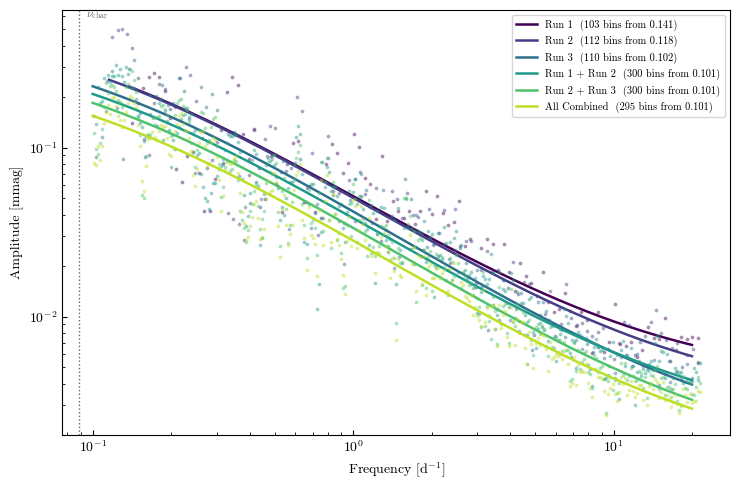

In [56]:
# THE FREEZE STEP. The continuum is fitted now, with only the rotation signal
# removed, and held fixed for the rest of the analysis. Re-fitting after a
# deep extraction is circular: every sinusoid fitted to red noise removes red
# power, the continuum comes out low, every S/N comes out high, and that
# justifies extracting more.
 
# 1. shape (nu_char, gamma) from the dataset with the best low-frequency
#    coverage, using the module's own 4-parameter iteration
d0 = data[RN_REFERENCE]
nyq0 = 0.5 / np.median(np.diff(np.sort(d0["time_binned"])))
print(f"red-noise SHAPE from {RN_REFERENCE} "
      f"(fit out to {RN_FMAX_FRAC*nyq0:.1f} d^-1)")
shape_rn, _, _ = pw.iterate_red_noise(
    d0["time_binned"], d0["flux_f1_and_2f1_removed_binned"],
    fmin=floor_for(RN_REFERENCE), fmax=RN_FMAX_FRAC * nyq0,
    oversample=4, snr_threshold=4.0,
    mask_width_rayleigh=2.0 * resfac(RN_REFERENCE),
    max_iter=6, verbose=True)
 
if not (0.15 < shape_rn["gamma"] < 11.5):
    raise RuntimeError("the reference red-noise fit hit the gamma bound -- "
                       "widen fmax so the white plateau is included, or pick "
                       "a different RN_REFERENCE")
print(f"  -> nu_char = {shape_rn['nu_char']:.4f} d^-1, "
      f"gamma = {shape_rn['gamma']:.2f}   (frozen from here on)")
 
# 2. levels per dataset, shape held fixed
RN = {}
for label in GMODE_SETS:
    d = data[label]
    t, y = d["time_binned"], d["flux_f1_and_2f1_removed_binned"]
    nyq = 0.5 / np.median(np.diff(np.sort(t)))
    print(f"\n{label}")
    rn, peaks = frozen_red_noise(
        t, y, shape_rn,
        fmin=floor_for(label), fmax=RN_FMAX_FRAC * nyq,
        mask_width=2.0 * resolution(label), verbose=True)
    RN[label] = rn
    if rn["alpha0"] < 0.5 * rn["C_white"]:
        print("    NOTE: alpha0 < C_white/2 -- no significant red component "
              "in this dataset; noise_model='box' would do as well.")
    D = segmented_band_D(t, y, floor_for(label))
    print(f"    D (segmented, high-passed at {floor_for(label):.3f} d^-1) "
          f"= {D:.2f}" + ("   -> correlated; a box is not defensible here"
                          if D > 2 else ""))
 
rn_summary = pd.DataFrame([
    {"run": k, "alpha0_mmag": v["alpha0"] * 1e3, "nu_char": v["nu_char"],
     "gamma": v["gamma"], "C_white_mmag": v["C_white"] * 1e3,
     "T_d": data[k]["T"]} for k, v in RN.items()])
print("\n" + rn_summary.to_string(index=False, float_format=lambda v: f"{v:.5f}"))
rn_summary.to_csv(os.path.join(OUT_DIR, "red_noise_frozen.csv"), index=False)
 
fig, ax = plt.subplots(figsize=(7.5, 5))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(RN)))
for (label, rn), c in zip(RN.items(), colors):
    ax.loglog(rn["binned_freq"], rn["binned_amp"] * 1e3, ".", ms=3.5,
              alpha=0.35, color=c)
    fp = np.logspace(np.log10(floor_for(label)), np.log10(20), 300)
    ax.loglog(fp, rn["model"](fp) * 1e3, lw=1.8, color=c,
              label=f"{label}  ({rn['n_bins']} bins from "
                    f"{rn['binned_freq'].min():.3f})")
ax.axvline(shape_rn["nu_char"], lw=1.0, ls=":", color="0.4")
ax.text(shape_rn["nu_char"], ax.get_ylim()[1], r"  $\nu_{\rm char}$",
        va="top", fontsize=8, color="0.4")
ax.set_xlabel(r"Frequency [d$^{-1}$]")
ax.set_ylabel("Amplitude [mmag]")
ax.legend(fontsize=7.5)
# ax.set_title("frozen red-noise continua (shape common, levels per dataset)",
#              fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "red_noise_frozen.pdf"), bbox_inches="tight")
plt.show()


## Spectra Check Plot

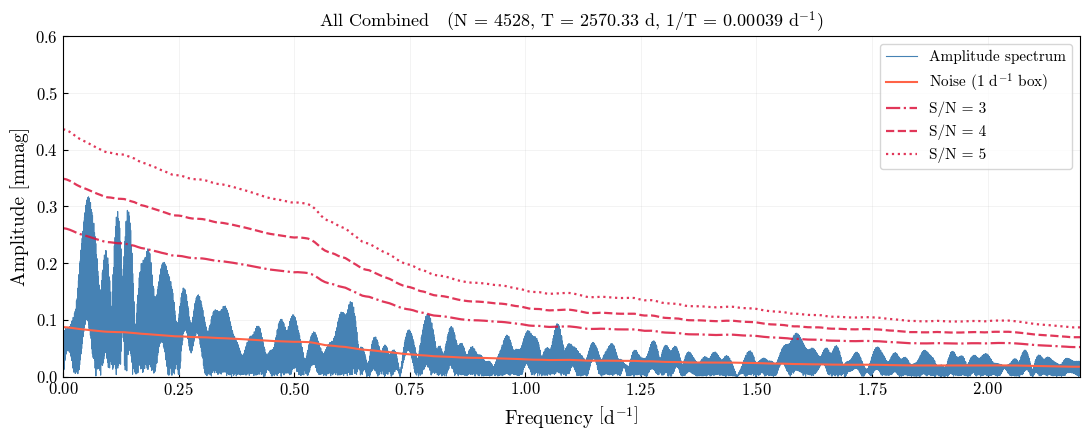

In [57]:
# ---- config ----
RUN        = "All Combined"          # any key in `data`
BAND       = (0, 2.2)
SNR_LEVELS = [3.0, 4.0, 5.0]
NOISE_BOX  = 1.0
OVERSAMPLE = 10
BINNED     = True
PREWHITENED = True            # False -> original flux, F1 and 2F1 still in
# ----------------

d = data[RUN]
if BINNED:
    t = d["time_binned"]
    y = d["flux_f1_and_2f1_removed_binned"] if PREWHITENED else d["flux_binned"]
else:
    t = d["time"]
    y = d["flux_f1_and_2f1_removed"] if PREWHITENED else d["flux"]

ray = pw.rayleigh(t)
fmin, fmax = BAND

grid = np.arange(max(fmin, ray / OVERSAMPLE), fmax, ray / OVERSAMPLE)
_, aspec = pw.amplitude_spectrum(t, y, freq=grid, method="ls")

# noise straight off the spectrum -- nothing removed
fr, ar = pw.amplitude_spectrum(t, y, fmin=max(fmin - NOISE_BOX, 1e-3),
                               fmax=fmax + NOISE_BOX, oversample=OVERSAMPLE,
                               method="ls")
gn = np.linspace(fmin, fmax, 300)
nz = np.array([pw.local_noise(fr, ar, f0, box=NOISE_BOX, exclude=1.5 * ray)
               for f0 in gn])

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(grid, aspec * 1e3, lw=0.8, color="steelblue", label="Amplitude spectrum")
ax.plot(gn, nz * 1e3, lw=1.5, color="tomato",
        label=f"Noise ({NOISE_BOX:g} d$^{{-1}}$ box)")
for s, ls in zip(SNR_LEVELS, ["-.", "--", ":"] * 3):
    ax.plot(gn, s * nz * 1e3, lw=1.6, ls=ls, color="crimson", alpha=0.85,
            label=f"S/N = {s:g}")

ax.set_xlim(fmin, fmax)
ax.set_ylim(0, 0.6)
ax.set_xlabel(r"Frequency $\left[\rm d^{-1}\right]$", fontsize=14)
ax.set_ylabel("Amplitude [mmag]", fontsize=14)
ax.set_title(f"{RUN}   (N = {len(t)}, T = {np.ptp(t):.2f} d, "
             rf"1/T = {ray:.5f} d$^{{-1}}$)", fontsize=13)
ax.tick_params(labelsize=12)
ax.grid(alpha=0.2, lw=0.5)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [59]:
# [V] Does the frozen continuum predict the real uncertainty at low frequency?
import time
from scipy.optimize import curve_fit

N_TRIALS_V  = 80
SNR_INJ_V   = 10.0          # M&O'D formulae are high-S/N asymptotics
DO_SCRAMBLE = False         # doubles runtime; enable once the rest works
V_RUNS      = ["Run 1", "Run 2", "Run 3", "Run 2 + Run 3", "All Combined"]
V_BANDS = {
    "g": dict(freqs=np.geomspace(0.15, 9.5, 5), binned=True,  band=(None, 10.0)),
    "p": dict(freqs=np.linspace(10.5, 70.0, 5), binned=False, band=(10.0, 70.0)),
}
K_A = np.sqrt(2 / np.pi)    # sigma_A = <A_noise> * sqrt(2/pi)
K_F = np.sqrt(6 / np.pi)    # sigma_f = <A_noise> * sqrt(6/pi) / (pi T A)

def _sine(t, A, f, phi, Z):
    return Z + A * np.sin(2.0 * np.pi * (f * t + phi))

def robust_std(x):
    x = np.asarray(x)
    return 1.4826 * np.median(np.abs(x - np.median(x)))

def injection_scatter(t, resid, f_inj, A_inj, n_trials, seed=0,
                      scramble=False, hw_ray=5.0):
    rng = np.random.default_rng(seed)
    t0 = t - t.min(); N = t.size; hw = hw_ray / np.ptp(t)
    rA, rf = [], []
    for _ in range(n_trials):
        noise = rng.permutation(resid) if scramble else np.roll(resid, rng.integers(N))
        phi = rng.uniform()
        y = _sine(t0, A_inj, f_inj, phi, 0.0) + noise
        try:
            p, _ = curve_fit(_sine, t0, y, p0=[A_inj, f_inj, phi, 0.0],
                             bounds=([0, f_inj - hw, -np.inf, -np.inf],
                                     [np.inf, f_inj + hw, np.inf, np.inf]),
                             maxfev=5000)
            rA.append(p[0]); rf.append(p[1])
        except RuntimeError:
            pass
    return dict(n_ok=len(rA), A_scatter=robust_std(rA), f_scatter=robust_std(rf))

rows, t_start = [], time.time()
for label in V_RUNS:
    d = data[label]
    for bname, cfg in V_BANDS.items():
        tk, yk = (("time_binned", "flux_f1_and_2f1_removed_binned") if cfg["binned"]
                  else ("time", "flux_f1_and_2f1_removed"))
        t, r = d[tk], d[yk]
        N, T = t.size, np.ptp(t)
        nyq = 0.5 / np.median(np.diff(np.sort(t)))
        f_lo = floor_for(label) if bname == "g" else cfg["band"][0]
        f_hi = min(cfg["band"][1], 0.9 * nyq)
        if f_hi <= f_lo:
            print(f"skip {label} {bname}: band above Nyquist"); continue

        D_b = segmented_band_D(t, r, f_lo)
        # flat white strawman: one level for the whole spectrum
        _, a_all = pw.amplitude_spectrum(t, r, fmin=f_lo, fmax=0.9 * nyq,
                                         oversample=2, method="ls")
        mean_white = float(np.mean(a_all))
        # what analyse() uses: mean over the searched band, times D
        _, a_band = pw.amplitude_spectrum(t, r, fmin=f_lo, fmax=f_hi,
                                          oversample=5, method="ls")
        mean_band = float(np.mean(a_band))

        for f_inj in cfg["freqs"]:
            if not (f_lo < f_inj < f_hi):
                continue
            _, ar_ = pw.amplitude_spectrum(t, r, fmin=max(f_inj - 1, f_lo),
                                           fmax=f_inj + 1, oversample=5, method="ls")
            mean_box = float(np.median(ar_)) / _RAY_MED_MEAN
            mean_red = float(RN[label]["model"](f_inj)) if cfg["binned"] else np.nan
            A_inj = SNR_INJ_V * mean_box

            emp = injection_scatter(t, r, f_inj, A_inj, N_TRIALS_V)
            shuf = (injection_scatter(t, r, f_inj, A_inj, N_TRIALS_V, scramble=True)
                    if DO_SCRAMBLE else None)
            rows.append(dict(
                run=label, band=bname, f_inj=f_inj, D_band=D_b, n_ok=emp["n_ok"],
                A_emp=emp["A_scatter"],
                A_shuf=shuf["A_scatter"] if shuf else np.nan,
                r_white=emp["A_scatter"] / (K_A * mean_white),
                r_pipe =emp["A_scatter"] / (K_A * mean_band * D_b),
                r_box  =emp["A_scatter"] / (K_A * mean_box),
                r_red  =emp["A_scatter"] / (K_A * mean_red),
                rf_box =emp["f_scatter"] / (K_F * mean_box / (np.pi * T * A_inj)),
                rf_red =emp["f_scatter"] / (K_F * mean_red / (np.pi * T * A_inj)),
            ))
            print(f"[{time.time()-t_start:6.1f}s] {label:9s} {bname}  "
                  f"f={f_inj:6.2f}  n_ok={emp['n_ok']}", flush=True)

val = pd.DataFrame(rows)
print("\nempirical scatter / predicted  (want ~1, and FLAT across f_inj)\n")
print(val[["run", "band", "f_inj", "D_band", "r_white", "r_pipe", "r_box",
           "r_red", "rf_box", "rf_red"]]
      .to_string(index=False, float_format=lambda v: f"{v:.3g}"))
print("\nper band: median [min-max] over runs and frequencies\n")
for b, g in val.groupby("band"):
    cells = [f"{c} {g[c].median():.2f} [{g[c].min():.2f}-{g[c].max():.2f}]"
             for c in ["r_white", "r_pipe", "r_box", "r_red"] if g[c].notna().any()]
    print(f"  {b}:  " + "   ".join(cells))

[   0.8s] Run 1     g  f=  0.15  n_ok=80
[   1.4s] Run 1     g  f=  0.42  n_ok=80
[   1.9s] Run 1     g  f=  1.19  n_ok=80
[   2.3s] Run 1     g  f=  3.37  n_ok=80
[   2.8s] Run 1     g  f=  9.50  n_ok=80
[   3.2s] Run 1     p  f= 10.50  n_ok=80
[   4.2s] Run 2     g  f=  0.15  n_ok=80
[   4.8s] Run 2     g  f=  0.42  n_ok=80
[   5.4s] Run 2     g  f=  1.19  n_ok=80
[   5.9s] Run 2     g  f=  3.37  n_ok=80
[   6.3s] Run 2     g  f=  9.50  n_ok=80
[   7.1s] Run 2     p  f= 10.50  n_ok=80
[   7.8s] Run 2     p  f= 25.38  n_ok=80
[   8.5s] Run 2     p  f= 40.25  n_ok=80
[   9.1s] Run 2     p  f= 55.12  n_ok=80
[  10.4s] Run 3     g  f=  0.15  n_ok=80
[  11.1s] Run 3     g  f=  0.42  n_ok=80
[  11.7s] Run 3     g  f=  1.19  n_ok=80
[  12.3s] Run 3     g  f=  3.37  n_ok=80
[  12.9s] Run 3     g  f=  9.50  n_ok=80
[  16.1s] Run 3     p  f= 10.50  n_ok=80
[  19.3s] Run 3     p  f= 25.38  n_ok=80
[  21.7s] Run 3     p  f= 40.25  n_ok=80
[  24.0s] Run 3     p  f= 55.12  n_ok=80
[  25.5s] Run 2 

## Analysis Function

In [ ]:
# [A]

COLS = ["ID", "ext_order", "freq", "amp", "phase", "period",
        "noise", "noise_box", "snr", "snr_box",
        "freq_err", "freq_err_mc", "amp_err", "amp_err_mc", "phase_err_mc", "D", "run"]
 
 
def analyse(t, t0, y, label, fmin, fmax,
            stop_mode="fixed", n_extract=N_EXTRACT_G, snr_cut=None,
            max_freqs=None, f_floor_abs=None, mc_iter=500,
            noise_model="red", rn_frozen=None, noise_box=1.0,
            resolution_factor=None, oversample=10, verbose=True):
    """
    One extraction, assessed once, at the end.
 
    stop_mode="fixed" extracts n_extract frequencies regardless of S/N and
    judges them afterwards against the FINAL residual spectrum and the frozen
    continuum. This decouples the stopping rule from the significance
    criterion. Setting snr_stop equal to the threshold you later apply -- what
    the old version did -- means every threshold runs a DIFFERENT search, so
    the lists are not nested and no survival statement can be made from them.
 
    Returns ONE table. Apply thresholds to `snr` afterwards.
    """
    if resolution_factor is None:
        resolution_factor = resfac(label)
    if f_floor_abs is None:
        f_floor_abs = floor_for(label)
    if max_freqs is None:
        max_freqs = max(n_extract, 40)
 
    ray = pw.rayleigh(t)
    f_lo = max(fmin, f_floor_abs)
 
    table, fit = pw.prewhiten(
        t, y, fmin=fmin, fmax=fmax, oversample=oversample,
        stop_mode=stop_mode, n_extract=n_extract,
        snr_stop=(snr_cut if stop_mode == "snr" else 0.0),
        max_freqs=max_freqs,
        noise_model=noise_model, noise_box=noise_box, rn_frozen=rn_frozen,
        resolution_factor=resolution_factor,
        search_method="ls", refit_tol=1e-10,
        f_floor_abs=f_lo, verbose=False)
 
    if table is None or table.empty:
        print(f"{label}: no frequencies extracted")
        return pd.DataFrame(columns=COLS)
 
    # ---- ONE uncapped simultaneous refit; these are the published numbers --
    seeds = table["freq"].values
    f2 = pw.fit_sinusoids(t, y, seeds, t0=t0, anchors=seeds,
                          refine_freqs=True, flim=(f_lo, fmax), tol=1e-12)
 
    # ---- significance, recomputed against THIS residual --------------------
    fr, ar = pw.amplitude_spectrum(t, f2["resid"], fmin=fmin, fmax=fmax,
                                   oversample=oversample, method="ls")
    excl = resolution_factor * ray
    nz_box = np.array([pw.local_noise(fr, ar, f, box=noise_box, exclude=excl)
                       for f in f2["freqs"]])
    nz_red = (np.asarray(rn_frozen["model"](f2["freqs"]), float)
              if rn_frozen is not None else np.full(f2["freqs"].size, np.nan))
    nz = nz_red if noise_model == "red" else nz_box
 
    # ---- uncertainties -----------------------------------------------------
    # The frozen continuum gives the LOCAL noise level at each candidate.
    # Converting it to a time-domain rms feeds Montgomery & O'Donoghue the
    # right sigma_m frequency by frequency. A single band-mean sigma is wrong
    # across a red band: it is set by the rise below ~0.3 d^-1 and overstates
    # the noise everywhere above it.
    #
    # apply_D=False and no explicit D factor: the continuum has already
    # absorbed the red excess that D exists to describe.
    D = segmented_band_D(t, f2["resid"], f_lo)      # reported, not applied
    if rn_frozen is not None:
        sigma_loc = np.asarray(rn_frozen["model"](f2["freqs"]), float) \
                    * np.sqrt(len(t) / np.pi)
    else:
        sigma_loc = nz_box * np.sqrt(len(t) / np.pi)

    err = pw.analytic_errors(t, f2["resid"], f2["amps"],
                             apply_D=False, sigma=sigma_loc)
    mc = pw.monte_carlo_errors(t, f2["freqs"], f2["amps"], f2["phases"],
                               f2["offset"], f2["t0"], f2["resid"],
                               n_iter=mc_iter, seed=42,
                               refit_freqs=MC_REFIT_FREQS_G,
                               noise_mode="red" if rn_frozen is not None else "block",
                               rn_model=rn_frozen["model"] if rn_frozen is not None else None)

    if np.isfinite(mc["freq_err"]).any():
        r = np.nanmedian(mc["freq_err"] / err["freq_err"])
        print(f"{label}: median freq_err_mc / freq_err_analytic = {r:.2f}"
                + ("   <- MC is much larger; analytic errors are optimistic"
                    if r > 2 else ""))
        
    out = pd.DataFrame({
        "ext_order": table["ID"].values,
        "freq": f2["freqs"], "amp": f2["amps"], "phase": f2["phases"],
        "period": 1.0 / f2["freqs"],
        "noise": nz, "noise_box": nz_box,
        "snr": f2["amps"] / nz, "snr_box": f2["amps"] / nz_box,
        "freq_err": err["freq_err"], "freq_err_mc": mc["freq_err"], "amp_err": err["amp_err"],
        "amp_err_mc": mc["amp_err"], "phase_err_mc": mc["phase_err"],
        "D": D, "run": label,
    }).sort_values("freq").reset_index(drop=True)
 
    n_before = len(out)
    out = pw.prune_unresolved(out, T=np.ptp(t),
                              resolution_factor=resolution_factor)
    if len(out) < n_before and verbose:
        print(f"{label}: pruned {n_before - len(out)} unresolved pair(s) at "
              f"{resolution_factor:.1f}/T = {resolution_factor/np.ptp(t):.5f} d^-1")
 
    out = out.reset_index(drop=True)
    out.insert(0, "ID", [f"F{i}" for i in range(1, len(out) + 1)])
    out.attrs.update(resolution=resolution_factor / np.ptp(t),
                     resolution_factor=resolution_factor,
                     f_floor=f_lo, D=D, #sigma_band=sig_band,
                     noise_model=noise_model, T=float(np.ptp(t)), N=int(t.size))
    return out

## SNR cutoff extraction loop for G_MODES

In [ ]:
# [G]
N_EXTRACT_G = 30
OUTPUT_DIR = os.path.join(ANALYSIS_DIR, "gmode_extraction")
os.makedirs(OUTPUT_DIR, exist_ok=True)

T_LONGEST_BLOCK = 50.1234                     # Run 3
env = 1.5 / T_LONGEST_BLOCK                   # 0.01995 d^-1
 
G_TABLES = {}
for label in GMODE_SETS:
    d = data[label]
    resolution_factor = max(1.5, env / pw.rayleigh(d["time_binned"]))
    G_TABLES[label] = analyse(
        d["time_binned"], T0_b, d["flux_f1_and_2f1_removed_binned"], label,
        fmin=GMODE_BAND[0], fmax=GMODE_BAND[1], mc_iter=MC_ITER,
        stop_mode="fixed", n_extract=N_EXTRACT_G,
        resolution_factor=resolution_factor, oversample=OVERSAMPLE,
        noise_model="red", rn_frozen=RN[label])
    tb = G_TABLES[label]
    tb.to_csv(os.path.join(OUTPUT_DIR, f"{label}_frequencies.csv"), index=False)
    print(f"{label:14s}: {len(tb):2d} kept, resolution "
          f"{tb.attrs['resolution']:.5f} d^-1 "
          f"({tb.attrs['resolution_factor']:.1f}/T), floor "
          f"{tb.attrs['f_floor']:.4f} d^-1, D = {tb.attrs['D']:.2f}")
 
rows = []
for label, tb in G_TABLES.items():
    for _, r in tb.iterrows():
        passed = [s for s in SNR_THR_LIST if r["snr"] >= s]
        rows.append({"run": label, "ID": r["ID"], "freq": r["freq"],
                     "amp_mmag": r["amp"] * 1e3, "snr": r["snr"],
                     "snr_box": r["snr_box"],
                     "max_snr_thr": max(passed) if passed else np.nan,
                     "n_thr": len(passed)})
survival = pd.DataFrame(rows).sort_values(["run", "freq"])
survival.to_csv(os.path.join(OUTPUT_DIR, "survival.csv"), index=False)
 
print("\ncount surviving each threshold:")
print(pd.DataFrame({
    f"S/N>={s}": {lbl: int((tb["snr"] >= s).sum())
                  for lbl, tb in G_TABLES.items()}
    for s in SNR_THR_LIST}).to_string())

Run 1: median freq_err_mc / freq_err_analytic = 1.09
Run 1: pruned 2 unresolved pair(s) at 1.5/T = 0.06897 d^-1
Run 1         : 28 kept, resolution 0.06897 d^-1 (1.5/T), floor 0.1379 d^-1, D = 5.48
Run 2: median freq_err_mc / freq_err_analytic = 1.07
Run 2: pruned 3 unresolved pair(s) at 1.5/T = 0.05775 d^-1
Run 2         : 27 kept, resolution 0.05775 d^-1 (1.5/T), floor 0.1154 d^-1, D = 7.58
Run 3: median freq_err_mc / freq_err_analytic = 0.84
Run 3: pruned 6 unresolved pair(s) at 1.5/T = 0.02994 d^-1
Run 3         : 24 kept, resolution 0.02994 d^-1 (1.5/T), floor 0.1000 d^-1, D = 7.62


KeyboardInterrupt: 

false alarm: 331 independent elements over 0.10-10.0 d^-1 (resolution 0.02993 d^-1)
  median 1.90, 84th 2.43, 99th 3.15, max 3.26

  at S/N = 4.02:
    Rayleigh  P(one element above) = 3.023e-06
    observed  P(one element above) = 0.000e+00   (none observed)

  tail fit: log P = +1.906 - 0.6693 k^2   (Rayleigh would be 0.000 - 0.7854 k^2)

  blind threshold for FAP = 0.001 over 331 elements:
    analytic (Rayleigh)          S/N > 4.02
    empirical tail extrapolated  S/N > 4.67
    largest value actually seen  S/N = 3.26  (one realisation constrains only the ~50% point)
  -> ADOPT S/N > 4.67

  for a frequency PREDICTED in advance (N_ind = 1, FAP 0.001):  S/N > 2.97

injecting at 0.0071, 0.0142, 0.0213, 0.0284, 0.0355, 0.0426, 0.0568, 0.0710 mmag (= [1, 2, 3, 4, 5, 6, 8, 10] x the median continuum, 0.0071 mmag)

 amp_mmag  A_over_noise  recovery_fraction  median_snr  snr_16  snr_84  frac_above_threshold
    0.007         1.000              1.000       2.289   1.774   2.773            

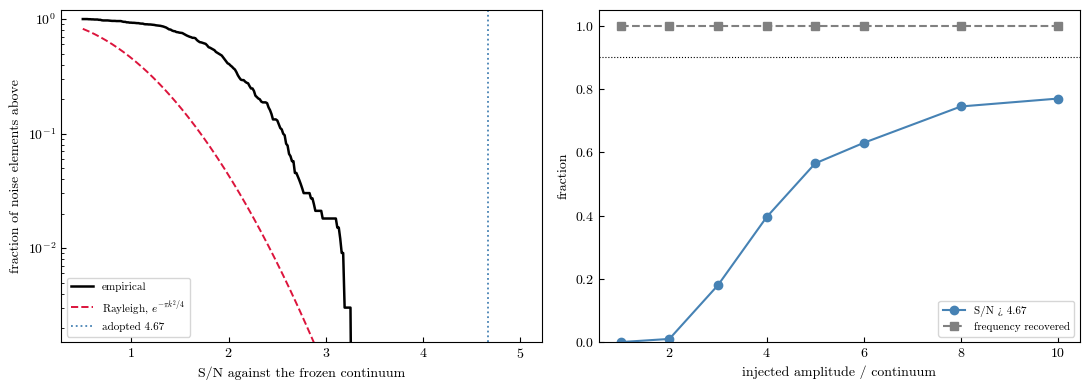

In [ ]:
# [I2]

INJ_RUN = "All Combined"
d = data[INJ_RUN]
t_inj = d["time_binned"]
rn_inj = RN[INJ_RUN]
ray_inj = pw.rayleigh(t_inj)
res_inj = resolution(INJ_RUN)
band = (floor_for(INJ_RUN), GMODE_BAND[1])
noise_fn = lambda f: rn_inj["model"](f)
 
fit_inj = pw.fit_sinusoids(t_inj, d["flux_f1_and_2f1_removed_binned"],
                           G_TABLES[INJ_RUN]["freq"].values, t0=T0_b,
                           anchors=G_TABLES[INJ_RUN]["freq"].values,
                           refine_freqs=True)
resid_inj = fit_inj["resid"]
 
# ---- 1. empirical false alarm, one value per INDEPENDENT element ---------
step = ray_inj / 10
grid_fa = np.arange(band[0], band[1] + step, step)
_, ag_fa = pw.amplitude_spectrum(t_inj, resid_inj, freq=grid_fa, method="ls")
snr_fa_spec = ag_fa / noise_fn(grid_fa)
 
centres = np.arange(band[0] + res_inj / 2, band[1], res_inj)
fa = np.array([snr_fa_spec[np.abs(grid_fa - c) <= res_inj / 2].max()
               for c in centres if (np.abs(grid_fa - c) <= res_inj / 2).any()])
N_IND = fa.size
 
print(f"false alarm: {N_IND} independent elements over "
      f"{band[0]:.2f}-{band[1]:.1f} d^-1 (resolution {res_inj:.5f} d^-1)")
print(f"  median {np.median(fa):.2f}, 84th {np.percentile(fa,84):.2f}, "
      f"99th {np.percentile(fa,99):.2f}, max {fa.max():.2f}")
 
# --- compare empirical vs Rayleigh AT A FIXED THRESHOLD ------------------
SNR_ANALYTIC = pw.snr_for_fap(TARGET_FAP, N_IND)
p_emp = float((fa >= SNR_ANALYTIC).mean())
p_ray = float(np.exp(-np.pi * SNR_ANALYTIC ** 2 / 4))
print(f"\n  at S/N = {SNR_ANALYTIC:.2f}:")
print(f"    Rayleigh  P(one element above) = {p_ray:.3e}")
print(f"    observed  P(one element above) = {p_emp:.3e}"
      + (f"   -> {p_emp/p_ray:.0f}x heavier" if p_emp > 0 else "   (none observed)"))
 
# --- fit the tail:  log P(>k) = c - a k^2   (Rayleigh: c=0, a=pi/4) ------
ks = np.linspace(np.percentile(fa, 50), fa.max() * 0.995, 60)
sf = np.array([(fa >= x).mean() for x in ks])
good = sf > 0
A = np.vstack([np.ones(good.sum()), -ks[good] ** 2]).T
c_fit, a_fit = np.linalg.lstsq(A, np.log(sf[good]), rcond=None)[0]
print(f"\n  tail fit: log P = {c_fit:+.3f} - {a_fit:.4f} k^2   "
      f"(Rayleigh would be 0.000 - {np.pi/4:.4f} k^2)")
if a_fit <= 0:
    raise RuntimeError("tail fit failed; inspect the S/N histogram by hand")

k    = np.linspace(0.5, max(5.0, fa.max() * 1.15), 300)
emp  = np.array([(fa >= x).mean() for x in k])
pred = np.exp(-np.pi * k**2 / 4)
tail = np.exp(c_fit - a_fit * k**2)

p_single = 1 - (1 - TARGET_FAP) ** (1 / N_IND)
SNR_TAIL = float(np.sqrt(max(c_fit - np.log(p_single), 0.0) / a_fit))
SNR_MAX_OBS = float(fa.max())
 
print(f"\n  blind threshold for FAP = {TARGET_FAP:g} over {N_IND} elements:")
print(f"    analytic (Rayleigh)          S/N > {SNR_ANALYTIC:.2f}")
print(f"    empirical tail extrapolated  S/N > {SNR_TAIL:.2f}")
print(f"    largest value actually seen  S/N = {SNR_MAX_OBS:.2f}  "
      f"(one realisation constrains only the ~50% point)")
SNR_ADOPT = float(max(SNR_ANALYTIC, SNR_TAIL, SNR_MAX_OBS))
print(f"  -> ADOPT S/N > {SNR_ADOPT:.2f}")
if a_fit < 0.8 * np.pi / 4:
    print("  *** tail heavier than Rayleigh: the continuum has NOT absorbed "
          "all the colour. The analytic FAP is optimistic; the adopted "
          "number is driven by the empirical tail. ***")
 
SNR_PRED = pw.snr_for_fap(TARGET_FAP_PREDICTED, 1)
print(f"\n  for a frequency PREDICTED in advance (N_ind = 1, FAP "
      f"{TARGET_FAP_PREDICTED:g}):  S/N > {SNR_PRED:.2f}")
 
# --- did the extraction go deep enough? ----------------------------------
if SNR_MAX_OBS > SNR_ANALYTIC:
    print(f"\n  *** the residual still contains a peak at S/N "
          f"{SNR_MAX_OBS:.2f}, above the analytic threshold. n_extract = "
          f"{N_EXTRACT_G} stopped too early -- raise it until the residual "
          f"maximum falls below the adopted threshold, otherwise the number "
          f"of detections depends on where you stopped. ***")
 
# ---- 2. completeness at the adopted threshold ----------------------------
nz_typ = float(np.median(noise_fn(np.linspace(*band, 200))))
INJ_AMPS = np.array(INJ_SNR_GRID) * nz_typ
print(f"\ninjecting at {', '.join(f'{a*1e3:.4f}' for a in INJ_AMPS)} mmag "
      f"(= {INJ_SNR_GRID} x the median continuum, {nz_typ*1e3:.4f} mmag)")
 
inj = pw.injection_recovery(
    t_inj, resid_inj, amplitudes=INJ_AMPS, freq_range=band,
    n_trials=INJ_TRIALS, tol_factor=resfac(INJ_RUN), oversample=5,
    mode="targeted", snr_threshold=SNR_ADOPT,
    noise_fn=lambda f: float(noise_fn(f)),      # <-- requires the patch
    seed=1, progress=False)
inj["amp_mmag"] = inj["amp_injected"] * 1e3
inj["A_over_noise"] = inj["amp_injected"] / nz_typ
print("\n" + inj[["amp_mmag", "A_over_noise", "recovery_fraction",
                  "median_snr", "snr_16", "snr_84", "frac_above_threshold"]]
      .to_string(index=False, float_format=lambda v: f"{v:.3f}"))
inj.to_csv(os.path.join(OUTPUT_DIR, "injection_recovery.csv"), index=False)
 
ok = inj[inj["frac_above_threshold"] >= 0.9]
if len(ok):
    print(f"\n90% complete above A = {ok['amp_mmag'].min():.4f} mmag "
          f"({ok['A_over_noise'].min():.1f} x the continuum)")
else:
    print("\nnever reaches 90% completeness -- extend INJ_SNR_GRID upward")
 
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(k, np.clip(emp, 1e-4, 1), lw=1.8, color="k", label="empirical")
ax[0].semilogy(k, pred, lw=1.4, ls="--", color="crimson",
               label=r"Rayleigh, $e^{-\pi k^2/4}$")
ax[0].axvline(SNR_ADOPT, lw=1.3, ls=":", color="steelblue",
              label=f"adopted {SNR_ADOPT:.2f}")
ax[0].set_ylim(0.5 / len(fa), 1.2)
ax[0].set_xlabel("S/N against the frozen continuum")
ax[0].set_ylabel("fraction of noise elements above")
ax[0].legend(fontsize=8)
ax[1].plot(inj["A_over_noise"], inj["frac_above_threshold"], "o-",
           color="steelblue", label=f"S/N > {SNR_ADOPT:.2f}")
ax[1].plot(inj["A_over_noise"], inj["recovery_fraction"], "s--",
           color="0.5", label="frequency recovered")
ax[1].axhline(0.9, lw=0.8, ls=":", color="k")
ax[1].set_xlabel("injected amplitude / continuum")
ax[1].set_ylabel("fraction")
ax[1].set_ylim(0, 1.05)
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "false_alarm_and_completeness.pdf"),
            bbox_inches="tight")
plt.show()

### Matching between runs 1to1

In [ ]:
def match_one_to_one(tables, anchor, required=None):
    labels = [l for l in tables if l != anchor]
    required = required or []
    A = tables[anchor].reset_index(drop=True)
    out = A[["ID", "freq", "amp", "snr", "snr_box"]].rename(
        columns={c: f"{anchor}_{c}" for c in ["freq", "amp", "snr", "snr_box"]}).copy()
    tols = {}
    for lab in labels:
        B = tables[lab].reset_index(drop=True)
        if B.empty:
            out[f"{lab}_freq"] = np.nan
            out[f"{lab}_amp"] = np.nan
            out[f"{lab}_dev_over_tol"] = np.nan
            continue
        tol = max(A.attrs["resolution"], B.attrs["resolution"])
        tols[lab] = tol
        pairs = sorted((abs(fa - fb), i, j)
                       for i, fa in enumerate(A["freq"].values)
                       for j, fb in enumerate(B["freq"].values)
                       if abs(fa - fb) <= tol)
        used_a, used_b, assign = set(), set(), {}
        for dev, i, j in pairs:
            if i in used_a or j in used_b:
                continue
            used_a.add(i), used_b.add(j)
            assign[i] = (j, dev)
        out[f"{lab}_freq"] = [B["freq"].values[assign[i][0]] if i in assign
                              else np.nan for i in range(len(A))]
        out[f"{lab}_amp"] = [B["amp"].values[assign[i][0]] if i in assign
                             else np.nan for i in range(len(A))]
        out[f"{lab}_dev_over_tol"] = [assign[i][1] / tol if i in assign
                                      else np.nan for i in range(len(A))]
    got = out[[f"{l}_freq" for l in labels]].notna()
    out["n_matched"] = got.sum(axis=1)
    out["consistent"] = (got[[f"{l}_freq" for l in required]].all(axis=1)
                         if required else out["n_matched"] > 0)
    out.attrs["tolerances"] = tols
    return out
 
 
matched = match_one_to_one(
    {k: v for k, v in G_TABLES.items() if not v.empty},
    anchor="All Combined", required=SINGLE_RUNS)
cols = ["ID", "All Combined_freq", "All Combined_amp", "All Combined_snr", "All Combined_snr_box"] \
    + [f"{l}_freq" for l in G_TABLES if l != "All Combined"] \
    + ["n_matched", "consistent"]
print(matched[cols].to_string(index=False, float_format=lambda v: f"{v:.5f}"))
matched.to_csv(os.path.join(OUTPUT_DIR, "matched_frequencies.csv"), index=False)
print("\ntolerances used:", {k: round(v, 5)
                             for k, v in matched.attrs["tolerances"].items()})
 
for lab in [l for l in G_TABLES if l != "All Combined"]:
    v = matched[f"{lab}_freq"].dropna()
    assert len(v) == v.nunique(), f"{lab}: a peak was matched more than once"
print("one-to-one assignment verified")
 
print("\nsurviving AND confirmed in all three individual runs:")
final = matched[(matched["All Combined_snr"] >= SNR_ADOPT)
                & matched["consistent"]]
print(final[cols].to_string(index=False, float_format=lambda v: f"{v:.5f}")
      if len(final) else "  none")
final.to_csv(os.path.join(OUTPUT_DIR, "final_candidates.csv"), index=False)

 ID  All Combined_freq  All Combined_amp  All Combined_snr  All Combined_snr_box  Run 1_freq  Run 2_freq  Run 3_freq  Run 1 + Run 2_freq  Run 2 + Run 3_freq  n_matched  consistent
 F1            0.10098           0.00018           1.18580               4.38068         NaN         NaN         NaN                 NaN             0.10041          1       False
 F2            0.13923           0.00029           2.29314               6.95312         NaN     0.12692     0.14022             0.12527             0.14084          4       False
 F3            0.18066           0.00024           2.23882               5.57344     0.17098         NaN     0.18179             0.17914             0.18012          4       False
 F4            0.21434           0.00025           2.56645               6.04142         NaN     0.23173     0.21694             0.22739             0.21927          4       False
 F5            0.26338           0.00017           1.98168               4.24863         NaN        

In [ ]:
COMB_MAX_HARM = 3
COMB_MAX_SIDE = 2
COMB_MIN_SUPPORT = 3
COMB_STRONGER_PARENT = True    # a harmonic cannot exceed its parent
 
 
def freq_lookup(matched, labels, anchor):
    out = {}
    for _, r in matched.iterrows():
        d = {anchor: float(r[f"{anchor}_freq"])}
        for lab in labels:
            v = r.get(f"{lab}_freq", np.nan)
            if np.isfinite(v):
                d[lab] = float(v)
        out[r["ID"]] = d
    return out
 
 
def combination_scan(matched, anchor, labels, f_rot, tols, snr_cut,
                     max_harm=COMB_MAX_HARM, max_side=COMB_MAX_SIDE,
                     min_support=COMB_MIN_SUPPORT,
                     stronger_parent=COMB_STRONGER_PARENT):
    look = freq_lookup(matched, labels, anchor)
    amp = {r["ID"]: float(r[f"{anchor}_amp"]) for _, r in matched.iterrows()}
    snr = {r["ID"]: float(r[f"{anchor}_snr"]) for _, r in matched.iterrows()}
    datasets = [anchor] + list(labels)
 
    rows = []
    for cid in [i for i in look if snr.get(i, 0) >= snr_cut]:
        cands, n_tried = [], 0
        for pid in list(look) + [None]:
            if pid == cid:
                continue
            if pid is not None and stronger_parent and amp[pid] <= amp[cid]:
                continue
            if pid is None:
                trials = [(f"{n}*Frot", None, 0, n) for n in range(1, max_harm + 1)]
            else:
                trials = [(f"{n}*{pid}", pid, n, 0) for n in range(2, max_harm + 1)]
                trials += [(f"{pid}{'+' if s>0 else '-'}{n}Frot", pid, 1, s * n)
                           for n in range(1, max_side + 1) for s in (+1, -1)]
            n_tried += len(trials)
            for name, par, mult, nrot in trials:
                devs, used = [], []
                for ds in datasets:
                    fc = look[cid].get(ds)
                    if fc is None:
                        continue
                    if par is None:
                        pred = nrot * f_rot
                    else:
                        fp = look[par].get(ds)
                        if fp is None:
                            continue
                        pred = mult * fp + nrot * f_rot
                    devs.append(abs(fc - pred) / tols[ds])
                    used.append(ds)
                if len(used) >= min_support:
                    cands.append((max(devs), np.mean(devs), name, par, len(used)))
        if cands:
            worst, mean, name, par, nds = min(cands)
            rows.append(dict(ID=cid, freq=look[cid][anchor], snr=snr[cid],
                             best_form=name, n_forms_tried=n_tried,
                             parent_over_child=(amp[par] / amp[cid] if par else np.nan),
                             n_datasets=nds, max_dev_over_tol=worst,
                             mean_dev_over_tol=mean))
        else:
            rows.append(dict(ID=cid, freq=look[cid][anchor], snr=snr[cid],
                             best_form="-", n_forms_tried=n_tried,
                             parent_over_child=np.nan, n_datasets=0,
                             max_dev_over_tol=10, mean_dev_over_tol=np.inf))
    df = pd.DataFrame(rows)
    if df.empty:
        return pd.DataFrame(columns=["ID", "freq", "snr", "best_form",
                                     "n_forms_tried", "parent_over_child",
                                     "n_datasets", "max_dev_over_tol",
                                     "mean_dev_over_tol", "worth_checking"])
    df["worth_checking"] = df["max_dev_over_tol"] <= 1.0
    return df
 
 
def test_relation(matched, anchor, labels, tols, child, parent=None,
                  mult=1, n_rot=0, f_rot=None, band=None, verbose=True):
    """
    Evaluate ONE named relation  f_child = mult * f_parent + n_rot * F_rot
    across every dataset. Because the relation is specified in advance, the
    chance rate is 2*tol/band per spectrum -- this IS a significance test.
    """
    f_rot = F_ROT if f_rot is None else f_rot
    band = (GMODE_BAND[1] - G_TABLES[anchor].attrs["f_floor"]) if band is None else band
    look = freq_lookup(matched, labels, anchor)
    name = (f"{mult}*{parent}" if parent else "") + \
           (f"{'+' if n_rot>0 else '-'}{abs(n_rot)}Frot" if n_rot else "")
    rows = []
    for ds in [anchor] + list(labels):
        fc = look.get(child, {}).get(ds)
        fp = look.get(parent, {}).get(ds) if parent else None
        if fc is None or (parent and fp is None):
            continue
        pred = (mult * fp if parent else 0.0) + n_rot * f_rot
        rows.append({"dataset": ds, "f_child": fc, "predicted": pred,
                     "deviation": abs(fc - pred),
                     "dev_over_tol": abs(fc - pred) / tols[ds],
                     "holds": abs(fc - pred) <= tols[ds]})
    # Dataframe with emptiness guard
    df = pd.DataFrame(rows)
    if df.empty:
        return pd.DataFrame(columns=["ID", "freq", "snr", "best_form",
                                     "n_forms_tried", "parent_over_child",
                                     "n_datasets", "max_dev_over_tol",
                                     "mean_dev_over_tol", "worth_checking"])
    # df["worth_checking"] = df["max_dev_over_tol"] <= 1.0
    # return df

    indep = [r for r in rows if not r["dataset"].startswith(("runs_", "combined"))]
    n_hold_indep = sum(r["holds"] for r in indep)
    if verbose:
        print(f"\n  {child} = {name}")
        print(df.to_string(index=False, float_format=lambda v: f"{v:.5f}"))
        p1 = 2 * tols[anchor] / band
        print(f"    holds in {int(df['holds'].sum())}/{len(df)} datasets "
              f"({n_hold_indep}/{len(indep)} independent runs)")
        if n_hold_indep == 0:
            print("    -> the relation does NOT hold; this hypothesis is rejected")
        else:
            print(f"    chance rate: {p1:.4f} per spectrum, "
                  f"{p1**n_hold_indep:.2e} for {n_hold_indep} independent runs")
    return df
 
 
ANCHOR = "All Combined"
LABELS = [l for l in G_TABLES if l != ANCHOR and not G_TABLES[l].empty]
TOLS = {ANCHOR: G_TABLES[ANCHOR].attrs["resolution"]}
TOLS.update({l: max(G_TABLES[ANCHOR].attrs["resolution"],
                    G_TABLES[l].attrs["resolution"]) for l in LABELS})
 
comb = combination_scan(matched, ANCHOR, LABELS, F_ROT, TOLS, SNR_ADOPT)
print(comb.to_string(index=False, float_format=lambda v: f"{v:.5f}"))
comb.to_csv(os.path.join(OUTPUT_DIR, "combination_scan.csv"), index=False)
 
nf = int(comb["n_forms_tried"].max()) if len(comb) else 0
bw = GMODE_BAND[1] - G_TABLES[ANCHOR].attrs["f_floor"]
p_any = nf * 2 * TOLS[ANCHOR] / bw
print(f"\n{nf} forms tried per candidate -> chance of SOME form matching in one "
      f"spectrum = {min(p_any,1):.2f}")
if p_any > 0.5:
    print("  *** saturated. Treat `worth_checking` as a shortlist, NOT as "
          "evidence. Confirm anything interesting with test_relation(). ***")
 
# --- the pre-specified test: is F20 the harmonic of F15? -----------------
print("\n" + "=" * 62)
print("PRE-SPECIFIED RELATION TEST")
print("=" * 62)
REL = test_relation(matched, ANCHOR, LABELS, TOLS,
                    child="F20", parent="F15", mult=2)
REL.to_csv(os.path.join(OUTPUT_DIR, "relation_F20_2xF15.csv"), index=False)
 
# controls: the same child against the rotation harmonic, and a null
test_relation(matched, ANCHOR, LABELS, TOLS, child="F20", n_rot=2)
test_relation(matched, ANCHOR, LABELS, TOLS, child="F15", n_rot=1)

Empty DataFrame
Columns: [ID, freq, snr, best_form, n_forms_tried, parent_over_child, n_datasets, max_dev_over_tol, mean_dev_over_tol, worth_checking]
Index: []

0 forms tried per candidate -> chance of SOME form matching in one spectrum = 0.00

PRE-SPECIFIED RELATION TEST

  F20 = 2*F15
      dataset  f_child  predicted  deviation  dev_over_tol  holds
 All Combined  1.00608    1.49391    0.48783      16.30126  False
        Run 1  1.01149    1.40123    0.38974       5.65115  False
        Run 3  1.00493    1.49053    0.48559      16.22055  False
Run 1 + Run 2  1.02319    1.52517    0.50198      16.77412  False
Run 2 + Run 3  1.00943    1.49394    0.48452      16.19038  False
    holds in 0/5 datasets (0/5 independent runs)
    -> the relation does NOT hold; this hypothesis is rejected

  F20 = +2Frot
      dataset  f_child  predicted  deviation  dev_over_tol  holds
 All Combined  1.00608    1.45797    0.45190      15.10039  False
        Run 1  1.01149    1.45797    0.44649       6.47

,dataset,f_child,predicted,deviation,dev_over_tol,holds
0,All Combined,0.746956,0.728987,0.017969,0.600435,True
1,Run 1,0.700614,0.728987,0.028373,0.411397,True
2,Run 2,0.702581,0.728987,0.026405,0.457271,True
3,Run 3,0.745263,0.728987,0.016276,0.543665,True
4,Run 1 + Run 2,0.762585,0.728987,0.033599,1.122715,False
5,Run 2 + Run 3,0.746971,0.728987,0.017984,0.600958,True


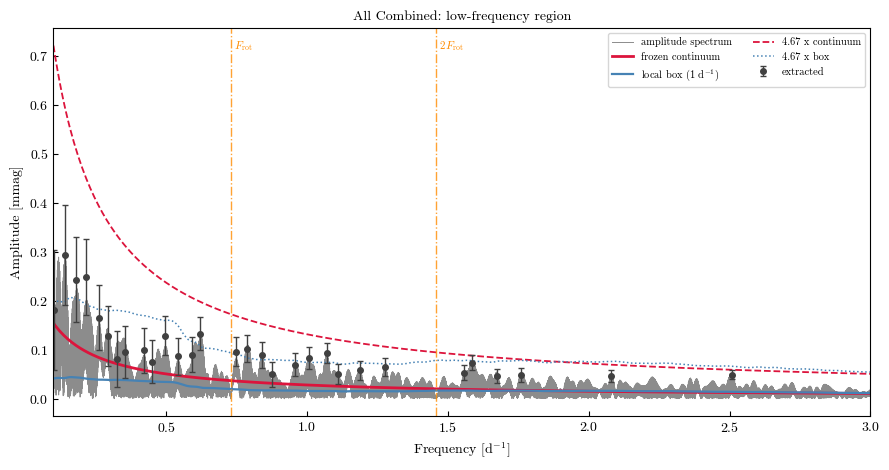

box/continuum: min 0.27, median 0.87, max 1.14


In [ ]:
LF_RUN, LF_BAND, LF_BOX = "All Combined", (0.10, 3.0), 1.0
d  = data[LF_RUN]; t = d["time_binned"]; y = d["flux_f1_and_2f1_removed_binned"]
rn = RN[LF_RUN]; tb = G_TABLES[LF_RUN]; ray = pw.rayleigh(t); res = resolution(LF_RUN)

step = ray / OVERSAMPLE
grid = np.arange(LF_BAND[0], LF_BAND[1] + step, step)
_, a = pw.amplitude_spectrum(t, y, freq=grid, method="ls")

fit_lf = pw.fit_sinusoids(t, y, tb["freq"].values, t0=T0_b,
                          anchors=tb["freq"].values, refine_freqs=True)
fr, ar = pw.amplitude_spectrum(t, fit_lf["resid"],
                               fmin=max(LF_BAND[0] - LF_BOX, 1e-3),
                               fmax=LF_BAND[1] + LF_BOX,
                               oversample=OVERSAMPLE, method="ls")
gn   = np.linspace(*LF_BAND, 400)
box  = np.array([pw.local_noise(fr, ar, f, box=LF_BOX, exclude=res) for f in gn])
cont = rn["model"](gn)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(grid, a * 1e3, lw=0.7, color="0.55", label="amplitude spectrum")
ax.plot(gn, cont * 1e3, lw=2.0, color="crimson", label="frozen continuum")
ax.plot(gn, box * 1e3, lw=1.6, color="steelblue",
        label=f"local box ({LF_BOX:g} d$^{{-1}}$)")
ax.plot(gn, SNR_ADOPT * cont * 1e3, lw=1.3, ls="--", color="crimson",
        label=f"{SNR_ADOPT:.2f} x continuum")
ax.plot(gn, SNR_ADOPT * box * 1e3, lw=1.1, ls=":", color="steelblue",
        label=f"{SNR_ADOPT:.2f} x box")
ax.errorbar(tb["freq"], tb["amp"] * 1e3, yerr=tb["amp_err_mc"] * 1e3,
            fmt="o", ms=4, color="0.25", lw=0, elinewidth=1, capsize=2,
            label="extracted")
sig = tb[tb["snr"] >= SNR_ADOPT]
if len(sig):
    ax.plot(sig["freq"], sig["amp"] * 1e3, "D", ms=9, mfc="none",
            mec="forestgreen", mew=1.8, label=f"S/N > {SNR_ADOPT:.2f}")
for f, lab in [(F_ROT, r" $F_{\rm rot}$"), (2 * F_ROT, r" $2F_{\rm rot}$")]:
    if LF_BAND[0] < f < LF_BAND[1]:
        ax.axvline(f, lw=1.0, ls="-.", color="darkorange", alpha=0.8)
        ax.text(f, ax.get_ylim()[1] * 0.97, lab, fontsize=8,
                color="darkorange", va="top")
ax.set_xlim(*LF_BAND) 
#ax.set_yscale("log")
ax.set_xlabel(r"Frequency [d$^{-1}$]")
ax.set_ylabel("Amplitude [mmag]")
ax.set_title(f"{LF_RUN}: low-frequency region", fontsize=10)
ax.legend(fontsize=7.5, ncol=2)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "lowfreq_noise.pdf"), bbox_inches="tight")
plt.show()
print(f"box/continuum: min {np.min(box/cont):.2f}, "
      f"median {np.median(box/cont):.2f}, max {np.max(box/cont):.2f}")

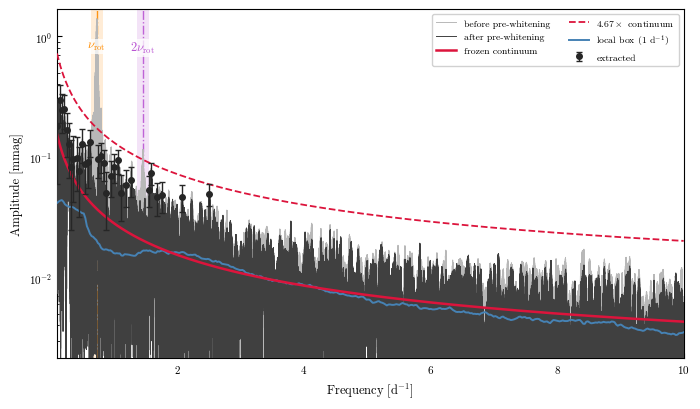

In [ ]:
LF_RUN, LF_BAND, LF_BOX = "All Combined", (0.1, 10.0), 1.0
d  = data[LF_RUN]; t = d["time_binned"]
y_pw   = d["flux_f1_and_2f1_removed_binned"]
y_orig = d.get("flux_binned", d.get("flux"))      # before pre-whitening
rn = RN[LF_RUN]; tb = G_TABLES[LF_RUN]
ray = pw.rayleigh(t); res = resolution(LF_RUN)

step = ray / OVERSAMPLE
grid = np.arange(LF_BAND[0], LF_BAND[1] + step, step)
_, a_orig = pw.amplitude_spectrum(t, y_orig, freq=grid, method="ls")
_, a_pw   = pw.amplitude_spectrum(t, y_pw,   freq=grid, method="ls")

fit_lf = pw.fit_sinusoids(t, y_pw, tb["freq"].values, t0=T0_b,
                          anchors=tb["freq"].values, refine_freqs=True)
fr, ar = pw.amplitude_spectrum(t, fit_lf["resid"],
                               fmin=max(LF_BAND[0] - LF_BOX, 1e-3),
                               fmax=LF_BAND[1] + LF_BOX,
                               oversample=OVERSAMPLE, method="ls")
gn   = np.linspace(*LF_BAND, 400)
box  = np.array([pw.local_noise(fr, ar, f, box=LF_BOX, exclude=res) for f in gn])
cont = rn["model"](gn)

fig, ax = plt.subplots(figsize=(7.1, 4.2))

# shade the two rotational peaks so the removal is visually obvious
for f0, c, lab in [(F_ROT, "darkorange", r"$\nu_{\rm rot}$"),
                   (2*F_ROT, "mediumorchid", r"$2\nu_{\rm rot}$")]:
    ax.axvspan(f0 - 3*res, f0 + 3*res, color=c, alpha=0.16, lw=0, zorder=0)
    ax.axvline(f0, lw=1.0, ls="-.", color=c, alpha=0.9, zorder=1)

ax.plot(grid, a_orig * 1e3, lw=0.7, color="0.72", zorder=2,
        label="before pre-whitening")
ax.plot(grid, a_pw   * 1e3, lw=0.7, color="0.25", zorder=3,
        label="after pre-whitening")

ax.plot(gn, cont * 1e3, lw=1.8, color="crimson", zorder=5,
        label="frozen continuum")
ax.plot(gn, SNR_ADOPT * cont * 1e3, lw=1.3, ls="--", color="crimson", zorder=5,
        label=rf"${SNR_ADOPT:.2f}\times$ continuum")
ax.plot(gn, box * 1e3, lw=1.4, color="steelblue", zorder=4,
        label=rf"local box ({LF_BOX:g} d$^{{-1}}$)")

ax.errorbar(tb["freq"], tb["amp"] * 1e3, yerr=tb["amp_err_mc"] * 1e3,
            fmt="o", ms=4, color="0.15", lw=0, elinewidth=1, capsize=2,
            zorder=6, label="extracted")
sig = tb[tb["snr"] >= SNR_ADOPT]
if len(sig):
    ax.plot(sig["freq"], sig["amp"] * 1e3, "D", ms=9, mfc="none",
            mec="forestgreen", mew=1.8, zorder=7,
            label=rf"S/N $>{SNR_ADOPT:.2f}$")

ax.set_yscale("log")
ax.set_xlim(*LF_BAND)
ax.set_ylim(0.5 * np.min(cont) * 1e3, 1.2 * np.max(a_orig) * 1e3)

lo, hi = ax.get_ylim()
for f0, c, lab in [(F_ROT, "darkorange", r"$\nu_{\rm rot}$"),
                   (2*F_ROT, "mediumorchid", r"$2\nu_{\rm rot}$")]:
    ax.text(f0, hi * 0.55, lab, fontsize=9, color=c,
            ha="center", va="top",
            bbox=dict(fc="white", ec="none", alpha=0.75, pad=1.2))

ax.set_xlabel(r"Frequency [d$^{-1}$]", fontsize=9)
ax.set_ylabel("Amplitude [mmag]", fontsize=9)
ax.tick_params(labelsize=8)
ax.legend(fontsize=7, ncol=2, loc="upper right", framealpha=0.9)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "lowfreq_prewhitening.pdf"),
            bbox_inches="tight", pad_inches=0.02)
plt.show()

## SNR Cutoff Extraction P_MODES

In [ ]:
SNR_THR_LIST = [2.0, 2.5]
OUTPUT_DIR_P = os.path.join(ANALYSIS_DIR, "snr_threshold_runs_pmodes")
os.makedirs(OUTPUT_DIR_P, exist_ok=True)

In [ ]:
PANELS = [(10.0, 72.0)]
REFERENCE = "Run 2"
NOISE_BOX = 2.0
OVERSAMPLE_PLOT = 10

COLORS  = {"Run 1":"grey", "Run 2":"cornflowerblue", "Run 3":"orangered",
           "Run 2 + Run 3":"forestgreen", "All Combined":"darkviolet"}
MARKERS = {"Run 1":"v", "Run 2":"o", "Run 3":"s",
           "Run 2 + Run 3":"^", "All Combined":"D"}

S/N 2.0: Run 2=9, Run 3=15, Run 2 + Run 3=15
S/N 2.5: Run 2=3, Run 3=12, Run 2 + Run 3=14


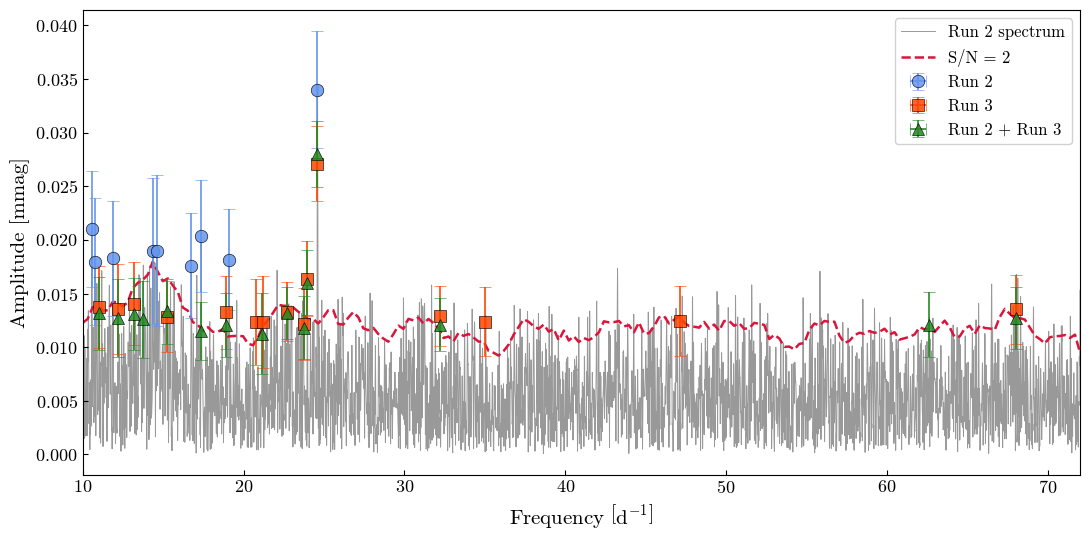

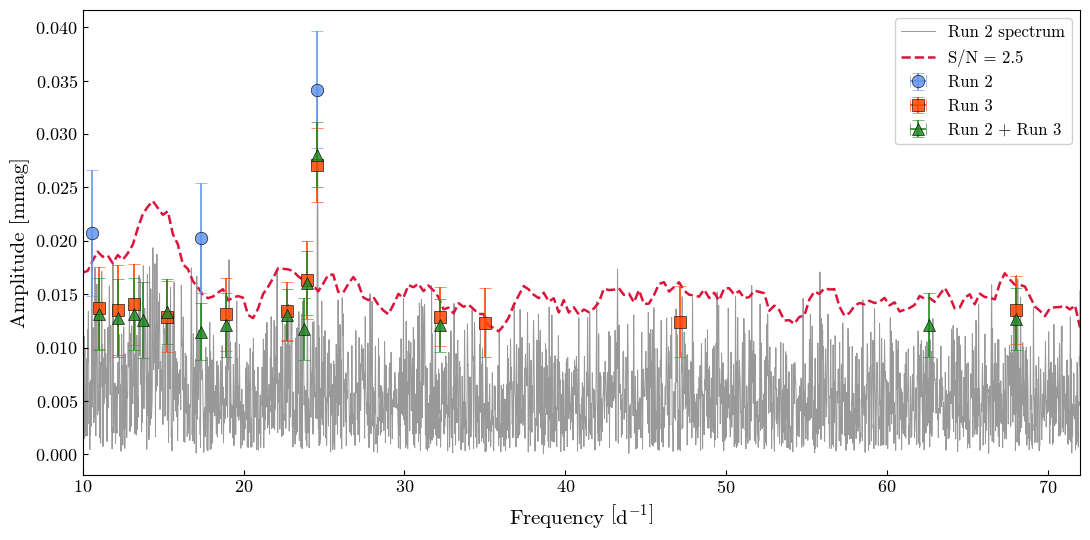

In [ ]:
survival_p = {} 
FMIN, FMAX = 10.0, 72.0

for snr_thr in SNR_THR_LIST:
    # Create a subdirectory for this SNR threshold
    snr_dir = os.path.join(OUTPUT_DIR_P, f"SNR_{snr_thr}")
    os.makedirs(snr_dir, exist_ok=True)

    tables = {}
    for label in ["Run 2", "Run 3", "Run 2 + Run 3"]:
        d = data[label]
        y = d["flux_f1_and_2f1_removed"]
        tables[label] = analyse(d["time"], T0, y, label,
                                fmin=FMIN, fmax=FMAX,
                                stop_mode="snr", snr_cut=snr_thr,
                                noise_model="box", rn_frozen=None,
                                max_freqs=15)
    for label, tb in tables.items():
        tb.to_csv(os.path.join(snr_dir, f"{label}_frequencies.csv"), index=False)
    print(f"S/N {snr_thr}: " +
          ", ".join(f"{k}={len(v)}" for k, v in tables.items()))

    # inside, after building `tables`
    for lbl, tb in tables.items():
        for f in tb["freq"]:
            survival_p.setdefault((lbl, round(f, 4)), []).append(snr_thr)
    
    # Generate and save the comparison plot
    fig, axes = plt.subplots(1, len(PANELS), figsize=(11, 5.5))
    axes = np.atleast_1d(axes)

    tref = data[REFERENCE]["time"]
    yref = data[REFERENCE].get("flux_f1_and_2f1_removed")
    ray = pw.rayleigh(tref)

    cref = tables[REFERENCE]["freq"].values
    fitr = pw.fit_sinusoids(tref, yref, cref, anchors=cref, refine_freqs=True)
    fr, ar = pw.amplitude_spectrum(
        tref, fitr["resid"], fmin=FMIN, fmax=FMAX,
        oversample=OVERSAMPLE_PLOT, method="ls"
    )

    for i, (ax, (fmin, fmax)) in enumerate(zip(axes, PANELS)):
        grid = np.arange(max(fmin, ray/OVERSAMPLE_PLOT), fmax, ray/OVERSAMPLE_PLOT)
        _, aspec = pw.amplitude_spectrum(tref, yref, freq=grid, method="ls")
        ax.plot(grid, aspec*1e3, lw=0.7, color="0.6", zorder=0,
                label=f"{REFERENCE} spectrum" if i == 0 else None)

        gn = np.linspace(fmin, fmax, 200)
        nz = np.array([pw.local_noise(fr, ar, f, box=NOISE_BOX, exclude=1.5*ray) for f in gn])
        ax.plot(gn, snr_thr * nz * 1e3, lw=1.8, ls="--", color="crimson",
                label=f"S/N = {snr_thr:g}" if i == 0 else None)

        for lbl, tb in tables.items():
            # base = lbl.replace(" (p)", "")
            sub = tb[(tb["freq"] >= fmin) & (tb["freq"] <= fmax)]
            if sub.empty:
                continue
            ax.errorbar(
                sub["freq"], sub["amp"]*1e3,
                xerr=sub["freq_err_mc"], yerr=sub["amp_err_mc"]*1e3,
                fmt=MARKERS[lbl], color=COLORS[lbl], ms=9,
                markeredgecolor="k", markeredgewidth=0.5,
                capsize=4, elinewidth=1.4, lw=0, alpha=0.85, zorder=3,
                label=lbl if i == 0 else None
            )

        ax.set_xlim(fmin, fmax)
        ax.set_xlabel(r"Frequency $\left[\rm d^{-1}\right]$", fontsize=15)
        ax.tick_params(labelsize=13)

    axes[0].set_ylabel("Amplitude [mmag]", fontsize=15)
    axes[0].legend(fontsize=12, loc="upper right", framealpha=0.9)
    plt.tight_layout()
    plt.savefig(
        os.path.join(snr_dir, "all_candidates_spectrum.pdf"),
        bbox_inches="tight", pad_inches=0.02
    )


['F8', 'F10', 'F11'] from Run 2 + Run 3: 22.691107, 23.960973, 24.594738 d^-1
Run 2 + Run 3: median freq_err_mc / freq_err_analytic = 1.11
Run 2 + Run 3: median amp_err_mc / amp_err_analytic = 1.17

ID          seed          freq     shift_ray     amp_mmag        phase   noise_mmag          snr     freq_err  freq_err_mc  amp_err_mmag  amp_err_mc_mmag  phase_err_mc          fap
F1 22.6911074961 22.6911068829 -0.0011432944 0.0129592965 0.4568602966 0.0032152613 4.0305577916 0.0000585397 0.0000661213  0.0025654074     0.0033954378  0.0469489209 0.2828315545
F2 23.9609732321 23.9609702329 -0.0055916059 0.0159467515 0.7301399432 0.0036301183 4.3929012798 0.0000537111 0.0000594992  0.0028964154     0.0032957064  0.0437140188 0.0297910206
F3 24.5947377409 24.5947371625 -0.0010783034 0.0281133343 0.9860461473 0.0040160018 7.0003290374 0.0000337052 0.0000310045  0.0032043059     0.0037359224  0.0236647444 0.0000000000

T = 1864.384 d, N = 24632, 1/T = 0.000536 d^-1, Nyquist = 216.0 d^-1
noise b

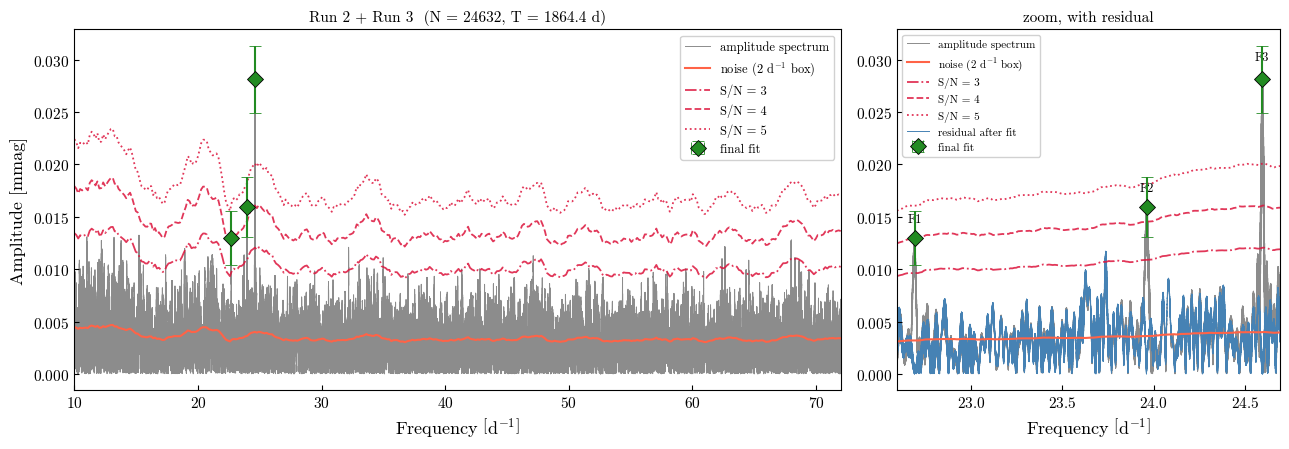

In [ ]:
# The new analyse() defaults to stop_mode="fixed" / noise_model="red". To keep
# the p-mode behaviour you already have:
#
#     tables[label] = analyse(d["time"], T0, y, label,
#                             fmin=FMIN, fmax=FMAX,
#                             stop_mode="snr", snr_cut=snr_thr,
#                             noise_model="box", rn_frozen=None,
#                             max_freqs=15)
#
# and use yerr=sub["amp_err"] in the plot, consistently with the g-mode cell.
#
# The non-nesting caveat still applies to the p-mode threshold scan: with
# snr_stop == snr_cut every threshold is a different search. If those
# residuals really are white the effect is small, and you can confirm that for
# free -- run once with stop_mode="fixed", n_extract=10 and check the S/N-cut
# sublists reproduce the scan. If they do, say so in the text; it is a
# one-line result that closes the question.
# %% [PM] --- p-mode: refit the three candidates alone, and plot ----------
# Takes the chosen candidates from the p-mode scan, refits the high-frequency
# spectrum with ONLY those three simultaneously, and plots them on the
# spectrum with the noise level and the S/N contours.
#
# Why refit with only three: the scan's table was produced by a run that
# extracted other frequencies too, and every frequency in a simultaneous
# solution affects every other one. If the three are what you intend to
# publish, the amplitudes and phases you quote must come from a solution
# containing exactly those three -- otherwise the numbers in the table belong
# to a model you are not reporting.
#
# Noise here stays a local BOX. These frequencies sit far above the red
# component, so a box is appropriate; the cell checks that assumption via D
# and warns if it fails.
 
# ---- config -------------------------------------------------------------
PM_RUN        = "Run 2 + Run 3"
PM_IDS        = ["F8", "F10", "F11"]   # from the p-mode scan table
PM_FREQS      = None                 # or an explicit list, overriding PM_IDS
PM_BAND       = (10.0, 72.0)
PM_ZOOM       = None                 # (lo, hi); None -> auto around the three
PM_NOISE_BOX  = 2.0                  # d^-1
PM_SNR_LEVELS = [3.0, 4.0, 5.0]
PM_MC_ITER    = 500
PM_BINNED     = False                # p-modes must use the UNBINNED series
# -------------------------------------------------------------------------
 
d = data[PM_RUN]
t = d["time_binned"] if PM_BINNED else d["time"]
y = (d["flux_f1_and_2f1_removed_binned"] if PM_BINNED
     else d["flux_f1_and_2f1_removed"])
t0 = T0_b if PM_BINNED else T0
ray = pw.rayleigh(t)
nyq = 0.5 / np.median(np.diff(np.sort(t)))
if PM_BAND[1] > nyq:
    raise ValueError(f"PM_BAND extends to {PM_BAND[1]} d^-1 but the Nyquist "
                     f"frequency of this series is {nyq:.2f} d^-1")
 
# ---- seed frequencies ---------------------------------------------------
if PM_FREQS is not None:
    seeds = np.sort(np.asarray(PM_FREQS, float))
    print(f"using explicit frequencies: "
          f"{', '.join(f'{f:.6f}' for f in seeds)}")
else:
    try:
        _src = PM_TABLES[PM_RUN]
    except NameError:
        _src = tables[PM_RUN]          # the last table built by the scan
    missing = [i for i in PM_IDS if i not in set(_src["ID"])]
    if missing:
        raise KeyError(f"{missing} not in the {PM_RUN} p-mode table. "
                       f"Available: {list(_src['ID'])}. Note the scan loop "
                       "overwrites `tables` each iteration, so this is the "
                       "LAST threshold only -- set PM_FREQS explicitly if you "
                       "meant a different one.")
    seeds = np.sort(_src.set_index("ID").loc[PM_IDS, "freq"].values.astype(float))
    print(f"{PM_IDS} from {PM_RUN}: "
          f"{', '.join(f'{f:.6f}' for f in seeds)} d^-1")
 
sep = np.diff(seeds)
if sep.size and sep.min() < 1.5 * ray:
    print(f"  WARNING: closest pair is {sep.min()/ray:.2f} Rayleigh apart "
          f"(< 1.5). These are not two resolved detections.")
 
# ---- refit with ONLY these three ----------------------------------------
fit3 = pw.fit_sinusoids(t, y, seeds, t0=t0, anchors=seeds, refine_freqs=True,
                        flim=PM_BAND, bound_rayleigh=0.5, tol=1e-12)
 
# noise from the residual, on a grid PADDED by the box width so that the box
# is never truncated at the band edge
fr, ar = pw.amplitude_spectrum(t, fit3["resid"],
                               fmin=max(PM_BAND[0] - PM_NOISE_BOX, 1e-3),
                               fmax=min(PM_BAND[1] + PM_NOISE_BOX, nyq),
                               oversample=OVERSAMPLE, method="ls")
nz = np.array([pw.local_noise(fr, ar, f, box=PM_NOISE_BOX, exclude=1.5 * ray)
               for f in fit3["freqs"]])
snr = fit3["amps"] / nz
 
# ---- uncertainties -----------------------------------------------------
# Local BOX noise here, not the continuum: these frequencies sit far above
# the red component. nz is already the local level at each candidate, so
# converting it to a time-domain rms gives sigma_m frequency by frequency.
# apply_D=False -- the local noise level already carries whatever excess
# power is present; D would double-count it.
D = segmented_band_D(t, fit3["resid"], PM_BAND[0])   # reported, not applied
sigma_loc = nz * np.sqrt(len(t) / np.pi)

err = pw.analytic_errors(t, fit3["resid"], fit3["amps"],
                         apply_D=False, sigma=sigma_loc)
mc = pw.monte_carlo_errors(t, fit3["freqs"], fit3["amps"], fit3["phases"],
                           fit3["offset"], fit3["t0"], fit3["resid"],
                           n_iter=PM_MC_ITER, seed=42, refit_freqs=True,
                           noise_mode="block")

r_freq = np.nanmedian(mc["freq_err"] / err["freq_err"])
r_amp  = np.nanmedian(mc["amp_err"] / err["amp_err"])
print(f"{PM_RUN}: median freq_err_mc / freq_err_analytic = {r_freq:.2f}")
print(f"{PM_RUN}: median amp_err_mc / amp_err_analytic = {r_amp:.2f}")


# ---- false alarm --------------------------------------------------------
# Valid here only because these residuals are white; D is the check.
n_ind = (PM_BAND[1] - PM_BAND[0]) * np.ptp(t)
fap = pw.false_alarm_probability(snr, n_ind)
snr_needed = pw.snr_for_fap(TARGET_FAP, n_ind)
 
pm = pd.DataFrame({
    "ID": [f"F{i}" for i in range(1, len(seeds) + 1)],
    "seed": seeds,
    "freq": fit3["freqs"],
    "shift_ray": (fit3["freqs"] - seeds) / ray,
    "amp_mmag": fit3["amps"] * 1e3,
    "phase": fit3["phases"],
    "noise_mmag": nz * 1e3,
    "snr": snr,
    "freq_err": err["freq_err"],
    "freq_err_mc": mc["freq_err"],
    "amp_err_mmag": err["amp_err"] * 1e3,
    "amp_err_mc_mmag": mc["amp_err"] * 1e3,
    "phase_err_mc": mc["phase_err"],
    "fap": fap,
})
print("\n" + pm.to_string(index=False, float_format=lambda v: f"{v:.10f}"))
print(f"\nT = {np.ptp(t):.3f} d, N = {t.size}, 1/T = {ray:.6f} d^-1, "
      f"Nyquist = {nyq:.1f} d^-1")
print(f"noise box = {PM_NOISE_BOX:g} d^-1, D = {D:.2f}, "
      f"residual rms = {np.std(fit3['resid'], ddof=1)*1e3:.4f} mmag")
print(f"independent elements in {PM_BAND[0]:g}-{PM_BAND[1]:g} d^-1: "
      f"{n_ind:.0f}  ->  S/N > {snr_needed:.2f} for a blind FAP of "
      f"{TARGET_FAP:g}")
if D > 2:
    print("  *** D > 2: these residuals are NOT white, so the analytic FAP "
          "above understates the false-alarm rate. Calibrate empirically "
          "instead (cell [I], with freq_range set to PM_BAND). ***")
if len(pm) and (fit3["amps"] > 20 * np.std(y, ddof=1)).any():
    print("  *** an amplitude exceeds 20x the data rms: the solve is "
          "degenerate, two frequencies have collided. ***")
 
pm.to_csv(os.path.join(OUT_DIR, f"pmode_{PM_RUN.replace(' ','_')}_final.csv"),
          index=False)
 
# ---- plot ---------------------------------------------------------------
if PM_ZOOM is None:
    pad = max(6 * ray, 0.05 * np.ptp(fit3["freqs"]) + 3 * ray)
    PM_ZOOM = (fit3["freqs"].min() - pad, fit3["freqs"].max() + pad)
 
step = ray / OVERSAMPLE
grid_full = np.arange(PM_BAND[0], PM_BAND[1], step)
grid_zoom = np.arange(PM_ZOOM[0], PM_ZOOM[1], step / 4)
_, a_full = pw.amplitude_spectrum(t, y, freq=grid_full, method="ls")
_, a_zoom = pw.amplitude_spectrum(t, y, freq=grid_zoom, method="ls")
_, r_zoom = pw.amplitude_spectrum(t, fit3["resid"], freq=grid_zoom, method="ls")
 
gn = np.linspace(PM_BAND[0], PM_BAND[1], 400)
nz_curve = np.array([pw.local_noise(fr, ar, f, box=PM_NOISE_BOX,
                                    exclude=1.5 * ray) for f in gn])
gz = np.linspace(*PM_ZOOM, 200)
nz_zoom = np.array([pw.local_noise(fr, ar, f, box=PM_NOISE_BOX,
                                   exclude=1.5 * ray) for f in gz])
 
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6),
                         gridspec_kw={"width_ratios": [2, 1]})
 
for ax, (g, a, gnn, nzz, xlim) in zip(
        axes, [(grid_full, a_full, gn, nz_curve, PM_BAND),
               (grid_zoom, a_zoom, gz, nz_zoom, PM_ZOOM)]):
    ax.plot(g, a * 1e3, lw=0.7, color="0.55", zorder=0,
            label="amplitude spectrum")
    ax.plot(gnn, nzz * 1e3, lw=1.5, color="tomato", zorder=2,
            label=rf"noise ({PM_NOISE_BOX:g} d$^{{-1}}$ box)")
    for s, ls in zip(PM_SNR_LEVELS, ["-.", "--", ":"]):
        ax.plot(gnn, s * nzz * 1e3, lw=1.3, ls=ls, color="crimson",
                alpha=0.85, zorder=2, label=f"S/N = {s:g}")
    ax.errorbar(fit3["freqs"], fit3["amps"] * 1e3,
                xerr=mc["freq_err"], yerr=mc["amp_err"] * 1e3,
                fmt="D", ms=8, color="forestgreen", markeredgecolor="k",
                markeredgewidth=0.6, capsize=4, elinewidth=1.5, lw=0,
                zorder=4, label="final fit")
    ax.set_xlim(*xlim)
    ax.set_xlabel(r"Frequency $\left[\rm d^{-1}\right]$", fontsize=13)
    ax.tick_params(labelsize=11)
 
axes[1].plot(grid_zoom, r_zoom * 1e3, lw=0.7, color="steelblue", zorder=1,
             label="residual after fit")
for f, idl in zip(fit3["freqs"], pm["ID"]):
    axes[1].annotate(idl, (f, np.interp(f, grid_zoom, a_zoom) * 1e3),
                     textcoords="offset points", xytext=(0, 11),
                     ha="center", fontsize=9)
 
axes[0].set_ylabel("Amplitude [mmag]", fontsize=13)
axes[0].set_title(f"{PM_RUN}  (N = {t.size}, T = {np.ptp(t):.1f} d)",
                  fontsize=11)
axes[1].set_title("zoom, with residual", fontsize=11)
axes[0].legend(fontsize=9, loc="upper right", framealpha=0.9)
axes[1].legend(fontsize=8, loc="upper left", framealpha=0.9)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, f"pmode_{PM_RUN.replace(' ','_')}_final.pdf"),
            bbox_inches="tight", pad_inches=0.02)
plt.show()

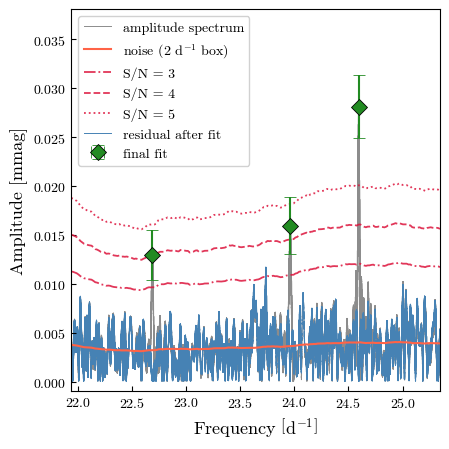

In [ ]:
PM_ZOOM = (fit3["freqs"].min() - 0.75, fit3["freqs"].max() + 0.75)
 
step = ray / OVERSAMPLE
grid_zoom = np.arange(PM_ZOOM[0], PM_ZOOM[1], step / 4)
_, a_full = pw.amplitude_spectrum(t, y, freq=grid_full, method="ls")
_, a_zoom = pw.amplitude_spectrum(t, y, freq=grid_zoom, method="ls")
_, r_zoom = pw.amplitude_spectrum(t, fit3["resid"], freq=grid_zoom, method="ls")
 
gn = np.linspace(PM_BAND[0], PM_BAND[1], 400)
nz_curve = np.array([pw.local_noise(fr, ar, f, box=PM_NOISE_BOX,
                                    exclude=1.5 * ray) for f in gn])
gz = np.linspace(PM_ZOOM[0], PM_ZOOM[1], 200)
nz_zoom = np.array([pw.local_noise(fr, ar, f, box=PM_NOISE_BOX,
                                   exclude=1.5 * ray) for f in gz])
 
fig, ax = plt.subplots(figsize=(4.6, 4.6))
 
g = grid_zoom
a = a_zoom
gnn = gz
nzz = nz_zoom

ax.plot(g, a * 1e3, lw=0.7, color="0.55", zorder=0,
        label="amplitude spectrum")

ax.plot(gnn, nzz * 1e3, lw=1.5, color="tomato", zorder=2,
        label=rf"noise ({PM_NOISE_BOX:g} d$^{{-1}}$ box)")

for s, ls in zip(PM_SNR_LEVELS, ["-.", "--", ":"]):
    ax.plot(gnn, s * nzz * 1e3, lw=1.3, ls=ls, color="crimson",
            alpha=0.85, zorder=2, label=f"S/N = {s:g}")

ax.errorbar(
    fit3["freqs"], fit3["amps"] * 1e3,
    xerr=mc["freq_err"], yerr=mc["amp_err"] * 1e3,
    fmt="D", ms=8, color="forestgreen", markeredgecolor="k",
    markeredgewidth=0.6, capsize=4, elinewidth=1.5, lw=0,
    zorder=4, label="final fit"
)
 
ax.plot(grid_zoom, r_zoom * 1e3, lw=0.7, color="steelblue", zorder=1,
             label="residual after fit")
for f, idl in zip(fit3["freqs"], pm["ID"]):
    axes[1].annotate(idl, (f, np.interp(f, grid_zoom, a_zoom) * 1e3),
                     textcoords="offset points", xytext=(0, 11),
                     ha="center", fontsize=9)

ax.set_ylim(-0.001, np.max(a_zoom) * 1.35 * 1e3)
ax.set_xlim(PM_ZOOM[0], PM_ZOOM[1])
ax.set_ylabel("Amplitude [mmag]", fontsize=13)
ax.set_xlabel(r"Frequency $\left[\rm d^{-1}\right]$", fontsize=13)
# ax.set_title("zoom, with residual", fontsize=11)
ax.legend(fontsize=10, loc="upper left", framealpha=0.9)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, f"pmode_spectrum_final.pdf"),
            bbox_inches="tight", pad_inches=0.02)
plt.show()

In [ ]:
p1 = 24.594737
p2 = 23.960970
p3 = 22.691107

d12 = p1 - p2
d23_h = (p2 - p3) / 2

print(f"P1 - P2 = {d12:.4f}")
print(f"P2 - P3 / 2 = {d23_h:.4f}")
print(f"Fraction of differences: {d23_h/d12:.6f}")

P1 - P2 = 0.6338
P2 - P3 / 2 = 0.6349
Fraction of differences: 1.001837


In [ ]:
# FAPs for the two weaker p-modes, under different search assumptions
W_TARGET = 0.0063        # declared half-window around a predicted position [d^-1]
BAND_P   = (10.0, 72.0)  # blind search band

T_p   = np.ptp(data[PM_RUN]["time"])
anch  = pm.loc[pm["snr"].idxmax()]
targ  = pm.drop(pm["snr"].idxmax())
n_bl  = (BAND_P[1] - BAND_P[0]) * T_p
n_tg  = len(targ) * 2 * W_TARGET * T_p          # family-wise over both slots

print(f"anchor {anch['ID']}  f = {anch['freq']:.5f}  S/N = {anch['snr']:.2f}")
print(f"T = {T_p:.1f} d | n_ind: blind {n_bl:,.0f}, targeted {n_tg:.0f}, exact 1")
print(f"S/N for FAP {TARGET_FAP:g}: blind {pw.snr_for_fap(TARGET_FAP, n_bl):.2f}, "
      f"targeted {pw.snr_for_fap(TARGET_FAP, n_tg):.2f}, "
      f"exact {pw.snr_for_fap(TARGET_FAP, 1):.2f}\n")
for _, r in targ.iterrows():
    print(f"{r['ID']}  f = {r['freq']:.5f}  S/N = {r['snr']:.2f}  |  FAP  "
          f"blind {pw.false_alarm_probability(r['snr'], n_bl):.3g}   "
          f"targeted {pw.false_alarm_probability(r['snr'], n_tg):.2g}   "
          f"exact {pw.false_alarm_probability(r['snr'], 1):.2g}")

anchor F3  f = 24.59474  S/N = 7.00
T = 1864.4 d | n_ind: blind 115,592, targeted 47, exact 1
S/N for FAP 0.001: blind 4.86, targeted 3.70, exact 2.97

F1  f = 22.69111  S/N = 4.03  |  FAP  blind 0.283   targeted 0.00014   exact 2.9e-06
F2  f = 23.96097  S/N = 4.39  |  FAP  blind 0.0298   targeted 1.2e-05   exact 2.6e-07


## Final Plot

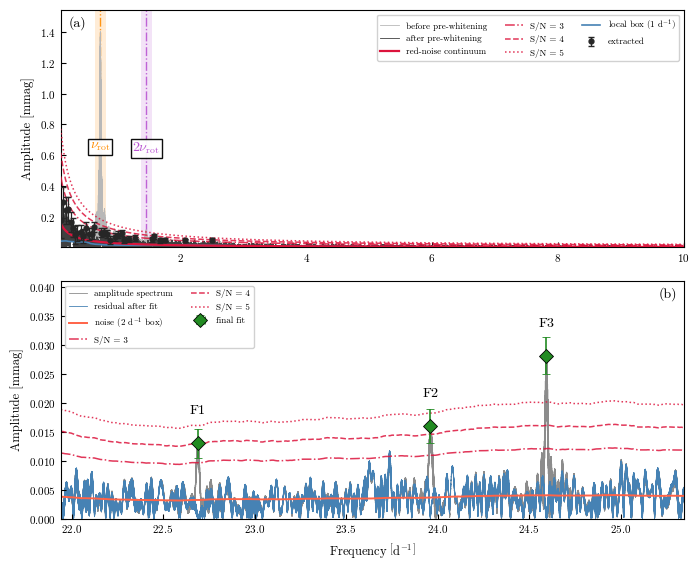

In [ ]:
# ============================ CONFIG =====================================
LF_RUN, LF_BAND, LF_BOX = "All Combined", (0.1, 10.0), 1.0
PM_RUN                  = "Run 2 + Run 3"          # unbinned: Nyquist matters
PM_PAD                  = 0.75                # d^-1 either side of the modes
SNR_LEVELS              = [3.0, 4.0, 5.0]
LS                      = ["-.", "--", ":"]
# =========================================================================

# ---- low-frequency panel data -------------------------------------------
d_lf   = data[LF_RUN]
t_lf   = d_lf["time_binned"]
y_lf   = d_lf["flux_f1_and_2f1_removed_binned"]
y_lf0  = d_lf["flux_binned"]                  # KeyError here = you never binned
                                              # the original; bin it first
ray_lf = pw.rayleigh(t_lf)
res_lf = resolution(LF_RUN)
rn     = RN[LF_RUN]
tb     = G_TABLES[LF_RUN]

step_lf = ray_lf / OVERSAMPLE
g_lf    = np.arange(LF_BAND[0], LF_BAND[1] + step_lf, step_lf)
_, a_lf0 = pw.amplitude_spectrum(t_lf, y_lf0, freq=g_lf, method="ls")
_, a_lf  = pw.amplitude_spectrum(t_lf, y_lf,  freq=g_lf, method="ls")

fit_lf = pw.fit_sinusoids(t_lf, y_lf, tb["freq"].values, t0=T0_b,
                          anchors=tb["freq"].values, refine_freqs=True)
fr_lf, ar_lf = pw.amplitude_spectrum(
    t_lf, fit_lf["resid"], fmin=max(LF_BAND[0] - LF_BOX, 1e-3),
    fmax=LF_BAND[1] + LF_BOX, oversample=OVERSAMPLE, method="ls")
gn_lf  = np.linspace(*LF_BAND, 400)
box_lf = np.array([pw.local_noise(fr_lf, ar_lf, f, box=LF_BOX,
                                  exclude=res_lf) for f in gn_lf])
cont   = rn["model"](gn_lf)

# ---- p-mode panel data ---------------------------------------------------
d_pm   = data[PM_RUN]
t_pm   = d_pm["time"]
y_pm   = d_pm["flux_f1_and_2f1_removed"]
ray_pm = pw.rayleigh(t_pm)
PM_ZOOM = (fit3["freqs"].min() - PM_PAD, fit3["freqs"].max() + PM_PAD)

g_pm = np.arange(PM_ZOOM[0], PM_ZOOM[1], ray_pm / (4 * OVERSAMPLE))
_, a_pm = pw.amplitude_spectrum(t_pm, y_pm, freq=g_pm, method="ls")
_, r_pm = pw.amplitude_spectrum(t_pm, fit3["resid"], freq=g_pm, method="ls")

fr_pm, ar_pm = pw.amplitude_spectrum(
    t_pm, fit3["resid"], fmin=PM_ZOOM[0] - PM_NOISE_BOX,
    fmax=PM_ZOOM[1] + PM_NOISE_BOX, oversample=OVERSAMPLE, method="ls")
gn_pm  = np.linspace(*PM_ZOOM, 300)
box_pm = np.array([pw.local_noise(fr_pm, ar_pm, f, box=PM_NOISE_BOX,
                                  exclude=1.5 * ray_pm) for f in gn_pm])

# ============================== FIGURE ===================================
fig, axes = plt.subplots(2, 1, figsize=(7.1, 5.8))
ax0, ax1 = axes

# ---------------- panel (a): low frequency, log y ------------------------
for f0, c in [(F_ROT, "darkorange"), (2 * F_ROT, "mediumorchid")]:
    if LF_BAND[0] < f0 < LF_BAND[1]:
        ax0.axvspan(f0 - 3 * res_lf, f0 + 3 * res_lf, color=c, alpha=0.16,
                    lw=0, zorder=0)
        ax0.axvline(f0, lw=1.0, ls="-.", color=c, alpha=0.9, zorder=1)

ax0.plot(g_lf, a_lf0 * 1e3, lw=0.6, color="0.72", zorder=2,
         label="before pre-whitening")
ax0.plot(g_lf, a_lf * 1e3, lw=0.6, color="0.25", zorder=3,
         label="after pre-whitening")
ax0.plot(gn_lf, cont * 1e3, lw=1.6, color="crimson", zorder=5,
         label="red-noise continuum")
for s, ls in zip(SNR_LEVELS, LS):
    ax0.plot(gn_lf, s * cont * 1e3, lw=1.1, ls=ls, color="crimson",
             alpha=0.85, zorder=5, label=f"S/N = {s:g}")
ax0.plot(gn_lf, box_lf * 1e3, lw=1.2, color="steelblue", zorder=4,
         label=rf"local box ({LF_BOX:g} d$^{{-1}}$)")

ax0.errorbar(tb["freq"], tb["amp"] * 1e3, yerr=tb["amp_err_mc"] * 1e3,
             fmt="o", ms=3.5, color="0.15", lw=0, elinewidth=0.9,
             capsize=2, zorder=6, label="extracted")
sig = tb[tb["snr"] >= SNR_ADOPT]
if len(sig):
    ax0.plot(sig["freq"], sig["amp"] * 1e3, "D", ms=8, mfc="none",
             mec="forestgreen", mew=1.6, zorder=7,
             label=rf"S/N $>{SNR_ADOPT:.2f}$")

ax0.set_yscale("linear")
ax0.set_xlim(*LF_BAND)
ax0.set_ylim(0.5 * cont.min() * 1e3, 1.1 * a_lf0.max() * 1e3)
for f0, c, lab in [(F_ROT, "darkorange", r"$\nu_{\rm rot}$"),
                   (2 * F_ROT, "mediumorchid", r"$2\nu_{\rm rot}$")]:
    if LF_BAND[0] < f0 < LF_BAND[1]:
        ax0.text(f0, ax0.get_ylim()[1] * 0.45, lab, fontsize=10, color=c,
                 ha="center", va="top",
                 bbox=dict(fc="white", ec="black", alpha=0.95, pad=1.2))
ax0.set_ylabel("Amplitude [mmag]", fontsize=9)
ax0.tick_params(labelsize=8)
ax0.legend(fontsize=6.5, ncol=3, loc="upper right", framealpha=0.9)
ax0.text(0.012, 0.93, "(a)", transform=ax0.transAxes, fontsize=10,
         fontweight="bold")

# ---------------- panel (b): p modes, linear y ---------------------------
ax1.plot(g_pm, a_pm * 1e3, lw=0.6, color="0.55", zorder=0,
         label="amplitude spectrum")
ax1.plot(g_pm, r_pm * 1e3, lw=0.6, color="steelblue", zorder=1,
         label="residual after fit")
ax1.plot(gn_pm, box_pm * 1e3, lw=1.4, color="tomato", zorder=2,
         label=rf"noise ({PM_NOISE_BOX:g} d$^{{-1}}$ box)")

ax1.errorbar(fit3["freqs"], fit3["amps"] * 1e3,
             xerr=mc["freq_err"], yerr=mc["amp_err"] * 1e3,
             fmt="D", ms=7, color="forestgreen", markeredgecolor="k",
             markeredgewidth=0.6, capsize=3, elinewidth=1.2, lw=0,
             zorder=4, label="final fit")

for s, ls in zip(SNR_LEVELS, LS):
    ax1.plot(gn_pm, s * box_pm * 1e3, lw=1.1, ls=ls, color="crimson",
             alpha=0.85, zorder=2, label=f"S/N = {s:g}")

for f, idl in zip(fit3["freqs"], pm["ID"]):
    ax1.annotate(idl, (f, np.interp(f, g_pm, a_pm) * 1e3 + 0.0025),
                 textcoords="offset points", xytext=(0, 10),
                 ha="center", fontsize=10)

ax1.set_xlim(*PM_ZOOM)
ax1.set_ylim(0, a_pm.max() * 1.45 * 1e3)
ax1.set_xlabel(r"Frequency $\left[\rm d^{-1}\right]$", fontsize=9)
ax1.set_ylabel("Amplitude [mmag]", fontsize=9)
ax1.tick_params(labelsize=8)
ax1.legend(fontsize=6.5, ncol=2, loc="upper left", framealpha=0.9)
ax1.text(0.96, 0.93, "(b)", transform=ax1.transAxes, fontsize=10,
         fontweight="bold")

fig.tight_layout(h_pad=1.2)
fig.savefig(os.path.join(OUT_DIR, "frequency_analysis_summary.pdf"),
            bbox_inches="tight", pad_inches=0.02)
plt.show()

(b) FAP 0.1% over 331 elements  -> S/N > 4.67
(c) FAP 0.1% over 115592 elements -> S/N > 4.86


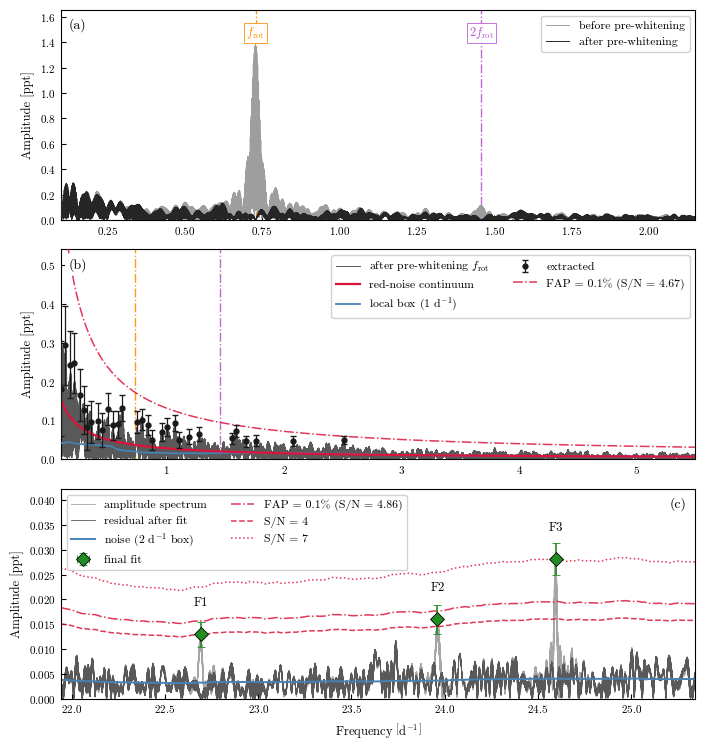

In [ ]:
# ============================ CONFIG =====================================
LF_RUN, LF_BAND, LF_BOX = "All Combined", (0.1, 5.5), 1.0
FROT_BAND               = (0.1, 2.15)
PM_RUN                  = "Run 2 + Run 3"
PM_PAD                  = 0.75
FAP_LF                  = 1e-3            # 0.01 %  -> panel (b)
FAP_PM                  = 1e-3            # 0.1 %   -> panel (c)
SNR_LEVELS_PM           = [4.0, 7.0]      # fixed S/N lines in panel (c)
LS_PM                   = ["--", ":"]
LS_FAP                  = "-."
# =========================================================================

# ---- FAP -> S/N thresholds -----------------------------------------------
# Low frequencies: red-noise region, so use the same rule as SNR_ADOPT
# (max of analytic, empirical-tail extrapolation, largest value seen).
# Needs N_IND, c_fit, a_fit, SNR_MAX_OBS from the false-alarm cell.
def snr_lf_for_fap(fap):
    p1 = 1.0 - (1.0 - fap) ** (1.0 / N_IND)
    s_an = pw.snr_for_fap(fap, N_IND)
    s_tail = float(np.sqrt(max(c_fit - np.log(p1), 0.0) / a_fit))
    return float(max(s_an, s_tail, SNR_MAX_OBS))

SNR_FAP_LF = snr_lf_for_fap(FAP_LF)

# ---- low-frequency data --------------------------------------------------
d_lf   = data[LF_RUN]
t_lf   = d_lf["time_binned"]
y_lf   = d_lf["flux_f1_and_2f1_removed_binned"]
y_lf0  = d_lf["flux_binned"]
ray_lf = pw.rayleigh(t_lf); res_lf = resolution(LF_RUN)
rn     = RN[LF_RUN]; tb = G_TABLES[LF_RUN]

step_lf  = ray_lf / OVERSAMPLE
g_lf     = np.arange(LF_BAND[0], LF_BAND[1] + step_lf, step_lf)
_, a_lf0 = pw.amplitude_spectrum(t_lf, y_lf0, freq=g_lf, method="ls")
_, a_lf  = pw.amplitude_spectrum(t_lf, y_lf,  freq=g_lf, method="ls")

fit_lf = pw.fit_sinusoids(t_lf, y_lf, tb["freq"].values, t0=T0_b,
                          anchors=tb["freq"].values, refine_freqs=True)
fr_lf, ar_lf = pw.amplitude_spectrum(
    t_lf, fit_lf["resid"], fmin=max(LF_BAND[0] - LF_BOX, 1e-3),
    fmax=LF_BAND[1] + LF_BOX, oversample=OVERSAMPLE, method="ls")
gn_lf  = np.linspace(*LF_BAND, 400)
box_lf = np.array([pw.local_noise(fr_lf, ar_lf, f, box=LF_BOX,
                                  exclude=res_lf) for f in gn_lf])
cont   = rn["model"](gn_lf)

# ---- p-mode data ---------------------------------------------------------
d_pm   = data[PM_RUN]
t_pm   = d_pm["time"]; y_pm = d_pm["flux_f1_and_2f1_removed"]
ray_pm = pw.rayleigh(t_pm)
PM_ZOOM = (fit3["freqs"].min() - PM_PAD, fit3["freqs"].max() + PM_PAD)

g_pm    = np.arange(PM_ZOOM[0], PM_ZOOM[1], ray_pm / (4 * OVERSAMPLE))
_, a_pm = pw.amplitude_spectrum(t_pm, y_pm, freq=g_pm, method="ls")
_, r_pm = pw.amplitude_spectrum(t_pm, fit3["resid"], freq=g_pm, method="ls")
fr_pm, ar_pm = pw.amplitude_spectrum(
    t_pm, fit3["resid"], fmin=PM_ZOOM[0] - PM_NOISE_BOX,
    fmax=PM_ZOOM[1] + PM_NOISE_BOX, oversample=OVERSAMPLE, method="ls")
gn_pm  = np.linspace(*PM_ZOOM, 300)
box_pm = np.array([pw.local_noise(fr_pm, ar_pm, f, box=PM_NOISE_BOX,
                                  exclude=1.5 * ray_pm) for f in gn_pm])

# p modes: residuals are white here, so the analytic FAP applies
N_IND_PM   = (PM_BAND[1] - PM_BAND[0]) * np.ptp(t_pm)
SNR_FAP_PM = pw.snr_for_fap(FAP_PM, N_IND_PM)

print(f"(b) FAP {FAP_LF*100:g}% over {N_IND} elements  -> S/N > {SNR_FAP_LF:.2f}")
print(f"(c) FAP {FAP_PM*100:g}% over {N_IND_PM:.0f} elements -> S/N > {SNR_FAP_PM:.2f}")

LAB_FAP_LF = rf"FAP = {FAP_LF*100:g}% (S/N = {SNR_FAP_LF:.2f})"
LAB_FAP_PM = rf"FAP = {FAP_PM*100:g}% (S/N = {SNR_FAP_PM:.2f})"

# ============================== FIGURE ===================================
fig, (ax0, ax1, ax2) = plt.subplots(3, 1, figsize=(7.1, 7.6))

ROT = [(F_ROT, "darkorange", r"$f_{\rm rot}$"),
       (2 * F_ROT, "mediumorchid", r"$2f_{\rm rot}$")]

# ---------------- (a) rotational signal and its removal ------------------
for f0, c, _ in ROT:
    if LF_BAND[0] < f0 < LF_BAND[1]:
        ax0.axvline(f0, lw=1.0, ls="-.", color=c, alpha=0.9, zorder=1)

ax0.plot(g_lf, a_lf0 * 1e3, lw=0.7, color="0.62", zorder=2,
         label="before pre-whitening")
ax0.plot(g_lf, a_lf * 1e3, lw=0.7, color="0.15", zorder=3,
         label="after pre-whitening")
ax0.set_xlim(*FROT_BAND)
ax0.set_ylim(0, 1.18 * a_lf0.max() * 1e3)
for f0, c, lab in ROT:
    if LF_BAND[0] < f0 < LF_BAND[1]:
        ax0.text(f0, ax0.get_ylim()[1] * 0.93, lab, fontsize=9, color=c,
                 ha="center", va="top",
                 bbox=dict(fc="white", ec=c, lw=0.6, alpha=0.95, pad=1.4))
ax0.tick_params(labelsize=8, labelbottom=True)
ax0.set_ylabel("Amplitude [ppt]", fontsize=9)
ax0.legend(fontsize=8.5, loc="upper right", framealpha=0.9)
ax0.text(0.012, 0.91, "(a)", transform=ax0.transAxes, fontsize=10,
         fontweight="bold")

# ---------------- (b) g-mode region, zoomed --------------------------------
for f0, c, _ in ROT:
    if FROT_BAND[0] < f0 < FROT_BAND[1]:
        ax1.axvline(f0, lw=1.0, ls="-.", color=c, alpha=0.9, zorder=1)

ax1.plot(g_lf, a_lf * 1e3, lw=0.7, color="0.35", zorder=2,
         label=r"after pre-whitening $f_{\rm rot}$")
ax1.plot(gn_lf, cont * 1e3, lw=1.6, color="crimson", zorder=5,
         label="red-noise continuum")
ax1.plot(gn_lf, SNR_FAP_LF * cont * 1e3, lw=1.1, ls=LS_FAP,
         color="crimson", alpha=0.85, zorder=5, label=LAB_FAP_LF)
ax1.plot(gn_lf, box_lf * 1e3, lw=1.3, color="steelblue", zorder=4,
         label=rf"local box ({LF_BOX:g} d$^{{-1}}$)")
ax1.errorbar(tb["freq"], tb["amp"] * 1e3, yerr=tb["amp_err_mc"] * 1e3,
             fmt="o", ms=3.5, color="0.10", lw=0, elinewidth=0.9,
             capsize=2, zorder=6, label="extracted")

ax1.set_xlim(*LF_BAND)
ax1.set_ylim(0, 0.75 * max((SNR_FAP_LF * cont).max(),
                           tb["amp"].max()) * 1e3)
ax1.tick_params(labelsize=8)
ax1.set_ylabel("Amplitude [ppt]", fontsize=9)

# ncol=2 fills column by column: left 3, right 2 (extracted + FAP)
h, l = ax1.get_legend_handles_labels()
order = [r"after pre-whitening $f_{\rm rot}$", "red-noise continuum",
         rf"local box ({LF_BOX:g} d$^{{-1}}$)",
         "extracted", LAB_FAP_LF]
idx = [l.index(k) for k in order if k in l]
ax1.legend([h[i] for i in idx], [l[i] for i in idx],
           fontsize=8.5, ncol=2, loc="upper right", framealpha=0.9)

ax1.text(0.012, 0.91, "(b)", transform=ax1.transAxes, fontsize=10,
         fontweight="bold", zorder=10,
         bbox=dict(fc="white", ec="none", alpha=1.0, pad=2.5))

# ---------------- (c) p modes ---------------------------------------------
ax2.plot(g_pm, a_pm * 1e3, lw=0.6, color="0.65", zorder=0,
         label="amplitude spectrum")
ax2.plot(g_pm, r_pm * 1e3, lw=0.6, color="0.35", zorder=1,
         label="residual after fit")
ax2.plot(gn_pm, box_pm * 1e3, lw=1.4, color="steelblue", zorder=2,
         label=rf"noise ({PM_NOISE_BOX:g} d$^{{-1}}$ box)")
ax2.plot(gn_pm, SNR_FAP_PM * box_pm * 1e3, lw=1.1, ls=LS_FAP,
         color="crimson", alpha=0.85, zorder=2, label=LAB_FAP_PM)
for s, ls in zip(SNR_LEVELS_PM, LS_PM):
    ax2.plot(gn_pm, s * box_pm * 1e3, lw=1.1, ls=ls, color="crimson",
             alpha=0.85, zorder=2, label=f"S/N = {s:g}")
ax2.errorbar(fit3["freqs"], fit3["amps"] * 1e3,
             xerr=mc["freq_err"], yerr=mc["amp_err"] * 1e3,
             fmt="D", ms=7, color="forestgreen", markeredgecolor="k",
             markeredgewidth=0.6, capsize=3, elinewidth=1.2, lw=0,
             zorder=4, label="final fit")
for f, idl in zip(fit3["freqs"], pm["ID"]):
    ax2.annotate(idl, (f, np.interp(f, g_pm, a_pm) * 1e3 + 0.0025),
                 textcoords="offset points", xytext=(0, 11),
                 ha="center", fontsize=9)

ax2.set_xlim(*PM_ZOOM)
ax2.set_ylim(0, max(a_pm.max() * 1.5,
                    max(SNR_LEVELS_PM) * box_pm.max() * 1.1) * 1e3)
ax2.tick_params(labelsize=8)
ax2.set_xlabel(r"Frequency $\left[\rm d^{-1}\right]$", fontsize=9)
ax2.set_ylabel("Amplitude [ppt]", fontsize=9)

# left column: spectra/noise/fit, right column: the three thresholds
h, l = ax2.get_legend_handles_labels()
order = ["amplitude spectrum", "residual after fit",
         rf"noise ({PM_NOISE_BOX:g} d$^{{-1}}$ box)", "final fit",
         LAB_FAP_PM] + [f"S/N = {s:g}" for s in SNR_LEVELS_PM]
idx = [l.index(k) for k in order if k in l]
ax2.legend([h[i] for i in idx], [l[i] for i in idx],
           fontsize=8.5, ncol=2, loc="upper left", framealpha=0.9)

ax2.text(0.96, 0.91, "(c)", transform=ax2.transAxes, fontsize=10,
         fontweight="bold")

fig.tight_layout(h_pad=0.9)
fig.savefig(os.path.join(OUT_DIR, "frequency_analysis_summary.pdf"),
            bbox_inches="tight", pad_inches=0.02)
plt.show()